---
# Documentation: https://wowchemy.com/docs/managing-content/

title: "Hilirisasi nikel: ekspornya 34 miliar dolar, yang nyangkut di kita berapa?"
subtitle: ""
summary: "Ekspor produk hilir nikel naik 20 kali lipat sejak larangan ekspor bijih. Tapi kalau dikurangi bijih, batubara, input impor, dan laba yang pulang ke pemilik modal asing, nilai tambah hilirisasi yang tertahan di Indonesia ternyata jauh lebih kecil."
authors: [admin]
tags: [nikel, hilirisasi, industri, perdagangan, larangan ekspor, nilai tambah]
categories: [Ekonomi, Perdagangan, Industri, Data & Kode]
date: 2026-10-19T00:00:00+07:00
lastmod: 2026-10-19T00:00:00+07:00
featured: false
draft: false

# Featured image
# To use, add an image named `featured.jpg/png` to your page's folder.
# Focal points: Smart, Center, TopLeft, Top, TopRight, Left, Right, BottomLeft, Bottom, BottomRight.
image:
  caption: ""
  focal_point: ""
  preview_only: false

# Projects (optional).
#   Associate this post with one or more of your projects.
#   Simply enter your project's folder or file name without extension.
#   E.g. `projects = ["internal-project"]` references `content/project/deep-learning/index.md`.
#   Otherwise, set `projects = []`.
projects: []
---

Udah lama ga nulis tentang hilirisasi nikel. Dulu saya nulis beberapa kali soal hilirisasi nikel di [blog ini]({{< relref "/post/stainlesssteel" >}}), di [The Conversation Indonesia](https://theconversation.com/klaim-sukses-hilirisasi-nikel-berbasis-larangan-ekspor-masih-memiliki-segudang-masalah-177735), dan di [East Asia Forum](https://eastasiaforum.org/2023/12/07/indonesia-doubles-down-on-nickel-export-bans-and-downstreaming/). Salah satu hal yang saya angkat adalah bahwa menggunakan nilai ekspor turunan nikel sebagai indikator keberhasilan nilai tambah domestik itu kurang tepat. Nilai ekspor produk turunan nikel itu angka **kotor** (_gross_). Di dalamnya menempel (_embodied_) banyak barang lain selain bijih nikel: batubara untuk listrik, ferokrom impor untuk baja nirkarat, sulfur/belerang impor untuk MHP, dan modal milik investor asing. Jadi kalau mau tahu hilirisasi berhasil atau tidak, nilai-nilai itu harus dikurangi dulu, lalu sisanya dibandingkan dengan _opportunity cost_-nya: berapa yang akan kita dapat kalau bijihnya (dan batubara serta barang lain) diekspor langsung.

bertahun-tahun berlalu, angka yang beredar tetap angka kotor. Ekspor produk hilir nikel sekarang sekitar **34 miliar dolar** setahun, dan angka ini sering dipakai sebagai bukti keberhasilan: dari 1,7 miliar dolar ekspor bijih di puncaknya jadi 34, naik 20 kali lipat!

Teorinya, larangan ekspor membuat harga bijih di dalam negeri tertekan, sehingga penambang domestik (banyak BUMN dan pengusaha lokal) dapat lebih sedikit. Sementara itu, nilai tambah dari pengolahan banyak mengalir ke pemilik modal asing, karena sebagian besar smelter dimiliki investor asing. Belum lagi barang lain yang aslinya bisa diekspor (batubara) maupun barang lain yang tidak kita impor andai ga hilirisasi (bijih Filipina, sulfur). Kalau dihitung bersih, jangan-jangan yang tertahan di Indonesia tidak lebih besar dari kalau kita ekspor bijihnya saja.

Post ini mencoba menghitungnya secara kasar buat iseng-iseng. Meski iseng, logikanya benar. Semua kode ada di bawah, dan bisa diperbaiki jika ada yang ternyata serius mau menghitungnya.

Pertama kita coba plot dulu manufacturing value added di beberapa industri dan daerah terkait. Sebagai penanda waktu, beberapa gambar di bawah memakai garis putus-putus bernomor:

1. 12 Januari 2014: larangan ekspor mineral mentah mulai berlaku.
2. 11 Januari 2017: relaksasi lewat PP 1/2017, bijih kadar di bawah 1,7% boleh diekspor lagi.
3. 1 Januari 2020: larangan ekspor bijih nikel berlaku kembali (diumumkan September 2019).
4. Juni 2021: HPAL pertama (Harita–Lygend di Pulau Obi) mulai produksi MHP.
5. 30 November 2022: panel WTO memenangkan Uni Eropa di sengketa DS592. Indonesia banding ke Appellate Body yang tidak berfungsi.
6. 3 Juli 2024: pabrik sel baterai HLI Green Power di Karawang diresmikan.
7. 26 April 2025: PP 19/2025 menaikkan royalti nikel. Di bulan yang sama, LG Energy Solution mundur dari proyek baterai terintegrasi senilai 8,4 miliar dolar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ink, merah, biru, abu = "#222222", "#c0392b", "#2c6fbb", "#999999"
emas, hijau, ungu = "#d4a017", "#2e8b57", "#7d3c98"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "axes.edgecolor": ink, "axes.labelcolor": ink, "xtick.color": ink,
                     "ytick.color": ink, "font.size": 10})

PERISTIWA = {2014.03: "1", 2017.03: "2", 2020.0: "3", 2021.47: "4", 2022.91: "5",
             2024.5: "6", 2025.31: "7"}

def garis_peristiwa(ax):
    lo, hi = ax.get_xlim()
    for x, lab in PERISTIWA.items():
        if not lo <= x <= hi:
            continue
        ax.axvline(x, color=abu, lw=0.8, ls="--", zorder=0)
        ax.text(x, 1.0, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8, color=abu)

## Apa kata PDB?

Kita mulai dari data PDB. Gambar 1 menunjukkan nilai tambah bruto (NTB) tiga lapangan usaha menurut harga konstan 2010, dalam triliun Rupiah, 2010–2025. Sumbu horizontal adalah tahun dan sumbu vertikal adalah NTB riil. Panel (a) adalah angka nasional dari PDB BPS. Panel (b) adalah PDRB gabungan Sulawesi Tengah (Morowali, IMIP) dan Maluku Utara (Weda Bay dan Obi), dua provinsi yang paling didominasi nikel. Data Sulawesi Tengah dihitung dari tabel distribusi persentase dikali total PDRB. Garis putus-putus bernomor adalah peristiwa di daftar atas.

Ada dua catatan soal data. Pertama, "pertambangan bijih logam" nasional juga berisi tembaga dan emas (Freeport, Amman), jadi panel (b) lebih bersih untuk nikel karena ga ada daerah lain dan di 2 tempat itu memang hanya ada nikel. Kedua, BPS tidak punya seri terpisah untuk baterai. Industri baterai (KBLI 2720) tergabung dalam "industri barang logam, komputer, elektronik, optik, dan peralatan listrik" (KBLI 25–27), jadi garis titik-titik di panel (a) adalah proksi yang sangat kasar.

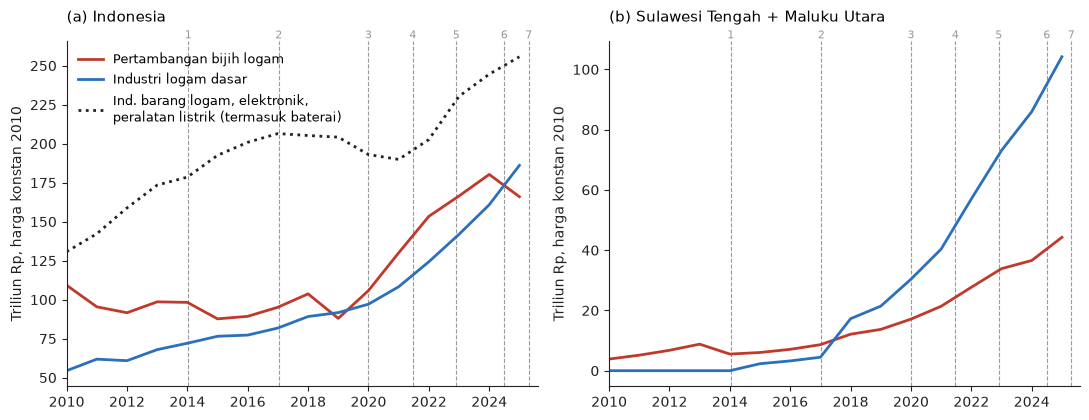

In [2]:
pdb = pd.read_csv("pdb_sektor.csv").query("periode == 'Tahunan' & harga == 'ADHK'")
pdb = pdb.pivot(index="tahun", columns="sektor", values="nilai") / 1e3      # triliun Rp
pdrb = pd.read_csv("pdrb_nikel.csv").query("harga == 'ADHK'")
pdrb = pdrb.groupby(["tahun", "sektor"]).nilai.sum().unstack() / 1e3         # Sulteng + Malut

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
seri = [("Pertambangan Bijih Logam", "Pertambangan bijih logam", merah, "-"),
        ("Industri Logam Dasar", "Industri logam dasar", biru, "-"),
        ("Industri Barang Logam, Elektronik, Peralatan Listrik",
         "Ind. barang logam, elektronik,\nperalatan listrik (termasuk baterai)", ink, ":")]
for col, lab, c, ls in seri:
    ax[0].plot(pdb.index, pdb[col], color=c, lw=2, ls=ls, label=lab)
for col, lab, c, ls in seri[:2]:
    ax[1].plot(pdrb.index, pdrb[col], color=c, lw=2, ls=ls, label=lab)
ax[0].set_title("(a) Indonesia", loc="left", fontsize=11, pad=14)
ax[1].set_title("(b) Sulawesi Tengah + Maluku Utara", loc="left", fontsize=11, pad=14)
for a in ax:
    a.set_xlim(2010, 2025.6)
    garis_peristiwa(a)
    a.set_ylabel("Triliun Rp, harga konstan 2010")
ax[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
plt.show()

Teori saya ternyata langsung kena koreksi pertama. Saya kira pertumbuhan pertambahang bakal melambat. Ternyata tidak. NTB riil pertambangan bijih logam nasional naik dari Rp88 T (2019) menjadi Rp180 T (2024), dan di Sulteng + Malut naik lebih dari tiga kali lipat, dari Rp14 T menjadi Rp44 T. Larangan ekspor tidak membuat bijih berhenti ditambang. Bijihnya pindah pembeli dari smelter di Tiongkok ke smelter di Morowali, dan volumenya malah meledak karena kapasitas smelter terus bertambah.

Industri logam dasar naik lebih cepat lagi. Secara nasional NTB riilnya dua kali lipat sejak 2019. Di Sulteng + Malut, dari praktis nol sebelum 2015 menjadi Rp104 T pada 2025. Sementara itu, KBLI 25–27, tempat industri baterai bersembunyi, nyaris datar sampai 2021. Kenaikannya sesudah itu belum tentu dari baterai, dan pabrik sel baterai pertama baru diresmikan pertengahan 2024. Jadi kalau ada "keberhasilan" hilirisasi, sejauh ini wujudnya adalah NPI dan baja nirkarat, bukan baterai. Ini sejalan dengan [CREA (2026)](https://energyandcleanair.org/wp/wp-content/uploads/2026/04/EN-CREA_Indonesias-nickel_-Aimed-at-EVs-but-still-parked-in-stainless-steel.pdf), yang mencatat 83% produksi nikel Indonesia tahun 2025 masih masuk ke baja nirkarat.

Perlu dicatat bahwa tren kenaikan logam dasar di Sulteng dan Malut tidak dimulai di 2020, ketika ekspor ban berlaku. Kenaikan tersebut sudah dimulai dari 2014. Buat yang lupa, UU Minerba (cikal bakal hilirisasi) diundangkan di 2009 dan ekspor ban nikel sebenarnya dilakukan 5 tahun kemudian yaitu di 2014. Hanya saja waktu itu pembangunan smelter cukup lambat sehingga larangan ekspor direlaksasi. Hal ini menguatkan satu teori bahwa sebenarnya hilirisasi ini tetap akan terjadi meskipun tidak ada larangan ekspor.

Tapi NTB harga konstan itu pada dasarnya indeks **volume**. Ia tidak bisa menjawab pertanyaan kita: berapa **harga** yang diterima penambang, dan **siapa** yang menikmati nilai tambahnya. Untuk itu kita perlu data perdagangan dan sedikit hitungan.

## Ekspor kotor

Gambar 2 adalah nilai ekspor Indonesia (miliar dolar AS, nilai FOB) untuk bijih nikel dan produk hilirnya, 2010–2025, dari UN Comtrade dengan Indonesia sebagai pelapor. Sumbu horizontal adalah tahun, sumbu vertikal adalah nilai ekspor yang ditumpuk per kelompok produk. Kodenya: bijih (HS 2604), feronikel/NPI (720260), baja nirkarat (7218, 7219, 7220), nikel matte (750110), MHP dan produk antara (750120), nikel olahan lain (7502, nikel sulfat 283324, kobalt oksida 2822), dan baterai Li-ion (850760). Angka 2020 sama persis dengan post 2022: feronikel USD4,74 miliar dan baja nirkarat ingot (7218) USD1,63 miliar.

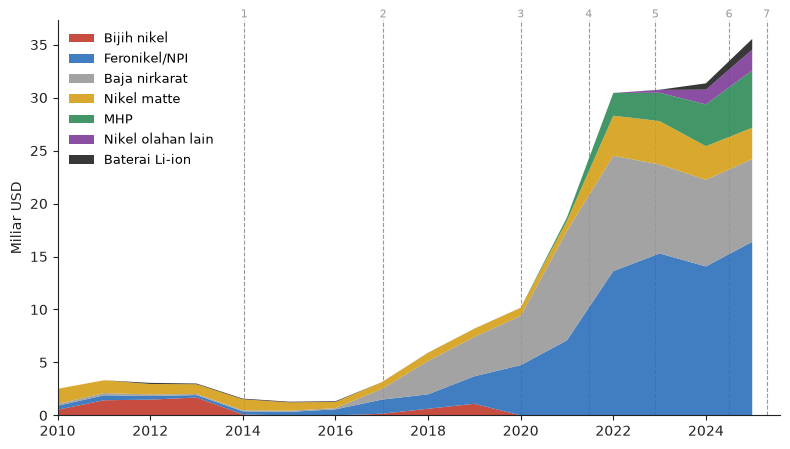

kel    Bijih nikel  Feronikel/NPI  Baja nirkarat  Nikel matte   MHP  \
tahun                                                                 
2013          1.69           0.23           0.10         0.92  0.00   
2019          1.10           2.60           3.71         0.78  0.00   
2020          0.00           4.74           4.66         0.76  0.00   
2022          0.00          13.62          10.89         3.78  2.14   
2024          0.00          14.06           8.18         3.18  3.95   
2025          0.00          16.39           7.82         2.95  5.41   

kel    Nikel olahan lain  Baterai Li-ion  
tahun                                     
2013                0.00            0.07  
2019                0.00            0.01  
2020                0.00            0.00  
2022                0.00            0.01  
2024                1.39            0.60  
2025                1.97            1.00  


In [3]:
ct = pd.read_csv("comtrade.csv", dtype={"cmdCode": str})
eks = (ct.query("job == 'idn_x' & partnerCode == 0").groupby(["period", "cmdCode"])
       [["primaryValue", "netWgt"]].sum().rename_axis(["tahun", "hs"]).reset_index())

KELOMPOK = {"2604": "Bijih nikel", "720260": "Feronikel/NPI", "7218": "Baja nirkarat",
            "7219": "Baja nirkarat", "7220": "Baja nirkarat", "750110": "Nikel matte",
            "750120": "MHP", "7502": "Nikel olahan lain", "283324": "Nikel olahan lain",
            "282200": "Nikel olahan lain", "850760": "Baterai Li-ion"}
warna = {"Bijih nikel": merah, "Feronikel/NPI": biru, "Baja nirkarat": abu, "Nikel matte": emas,
         "MHP": hijau, "Nikel olahan lain": ungu, "Baterai Li-ion": ink}
g = (eks.assign(kel=eks.hs.map(KELOMPOK)).groupby(["tahun", "kel"]).primaryValue.sum()
     .unstack().reindex(columns=list(warna)).fillna(0) / 1e9)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.stackplot(g.index, g.T.values, colors=list(warna.values()), labels=list(warna), alpha=0.9)
ax.set_xlim(2010, 2025.6)
garis_peristiwa(ax)
ax.set_ylabel("Miliar USD")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
plt.show()
print(g.round(2).loc[[2013, 2019, 2020, 2022, 2024, 2025]])

Lonjakannya memang luar biasa. Ekspor bijih di puncaknya (2013) USD1,7 miliar. Ekspor produk hilir 2025 sekitar USD34,5 miliar: feronikel/NPI USD16,4 miliar, baja nirkarat USD7,8 miliar, MHP USD5,4 miliar, matte USD3,0 miliar, dan sisanya produk olahan lain serta baterai. Baterai Li-ion akhirnya muncul, USD1 miliar di 2025. Matte sebenarnya bukan produk baru: PT Inco (sekarang Vale Indonesia) sudah mengekspor matte sejak puluhan tahun lalu.

Perbandingan "1,7 jadi 34" inilah yang sering dikutip. Masalahnya, perbandingan ini apel dengan jeruk. Angka 1,7 miliar itu hampir seluruhnya nilai tambah domestik (penambangnya di Indonesia), sedangkan 34 miliar itu nilai kotor yang di dalamnya ada bijih, batubara, belerang impor, dan laba investor asing. Mari kita bongkar satu per satu.

## Harga bijih dan batubara

Komponen pertama yang perlu dibongkar adalah bijih. Setelah ekspor dilarang, penambang hanya punya satu jenis pembeli: smelter di dalam negeri, yang jumlahnya sedikit dan banyak di antaranya satu grup usaha. Ini pasar monopsoni, atau tepatnya oligopsoni. Pemerintah mencoba melindungi penambang dengan Harga Patokan Mineral (HPM). Sebelum 2026, rumusnya kira-kira begini:

$$
  \begin{align*}
  HPM_t &= g \cdot CF(g) \cdot P^{LME}_t \cdot (1-m) \newline
  CF(g) &= 17\% + \frac{g - 1{,}6\%}{0{,}1\%} \times 1\%
  \end{align*}
$$

di mana $g$ adalah kadar nikel bijih, $CF(g)$ adalah _corrective factor_ yang besarnya 17% pada kadar 1,6% dan naik atau turun 1 poin untuk setiap 0,1% kadar, $P^{LME}_t$ adalah harga nikel dunia (Pink Sheet Bank Dunia), dan $m$ adalah kadar air (35%). Untuk bijih saprolit kadar 1,7%, rumus ini memberi HPM sekitar USD27 per ton basah di 2020 dan sekitar USD37 di 2021. Angka ini cocok dengan HPM 1,8% yang diberitakan, yaitu USD30,15 di Juli 2020 dan USD40–42 di Oktober 2021. Satu catatan: HPM resmi memakai harga nikel periode sebelumnya, sedangkan saya memakai rata-rata tahun berjalan. Waktu harga nikel turun (2023–2024), HPM resmi kemungkinan sedikit di atas angka saya.

Masalahnya, HPM tidak selalu dipatuhi. Pada Juli 2020 smelter dilaporkan membeli bijih 1,8% di kisaran USD20 per ton, jauh di bawah HPM ([Kontan](https://industri.kontan.co.id/news/smelter-lokal-tolak-harga-patokan-penambang-minta-ekspor-bijih-nikel-dibuka)), dan perselisihan harga ini masih terjadi di akhir 2021 ([CNBC Indonesia](https://www.cnbcindonesia.com/news/20211028122600-4-287205/drama-harga-bijih-nikel-ke-smelter-domestik-belum-berakhir)). Belakangan situasinya berbalik. Ketika bijih jadi rebutan, transaksi terjadi **di atas** HPM, dengan premi sekitar USD15–17 di akhir 2024 dan USD26–28 di pertengahan 2025 ([SMM](https://news.metal.com/newscontent/103111356)). Jadi harga domestik yang saya pakai adalah HPM ditambah premi, atau dikurangi diskon: −USD10 (2020), −USD5 (2021), nol (2022), lalu +USD5, +USD12, dan +USD24 untuk 2023–2025. Semua angka premi dan diskon ini tebakan berdasarkan berita.

**Harga dunia.** Ini bagian yang agak tricky, karena sejak 2020 Indonesia tidak lagi mengekspor bijih, jadi tidak ada harga ekspor bijih Indonesia. Saya memakai harga bijih Filipina, eksportir bijih nikel terbesar dunia sekarang, yang dibayar Tiongkok. Angkanya adalah nilai impor dibagi berat impor Tiongkok dari Filipina (CIF, UN Comtrade), disetarakan ke kadar 1,7%, lalu dikurangi ongkos kapal USD10 per ton:

$$
p^{A}_t = \frac{P^{CIF,PH}_t}{g_{PH}} \cdot g - f
$$

di mana $P^{CIF,PH}_t$ adalah harga impor Tiongkok untuk bijih Filipina, $g_{PH}$ = 1,4% adalah tebakan kadar rata-rata bijih Filipina (lebih rendah dari Indonesia), $g$ = 1,7%, dan $f$ adalah ongkos kapal. Ini **batas A**.

Kenapa tidak memakai data ekspor bijih Indonesia sebelum larangan? Karena datanya aneh. Untuk pengiriman yang sama, harga FOB versi BPS/Comtrade Indonesia ternyata cuma **29–57%** dari harga CIF yang dicatat Tiongkok untuk bijih dari Indonesia. Selisih sebesar itu tidak mungkin cuma ongkos kapal, jadi kemungkinan besar ada _under-invoicing_. Data Tiongkok justru menunjukkan bahwa selama relaksasi 2017–2019, bijih Indonesia dihargai kurang lebih **sama** dengan bijih Filipina per satuan nikel (rasionya 0,85–1,19). Jadi patokan Filipina cukup masuk akal.

Tapi batas A tetap terlalu mahal, karena kalau Indonesia ikut membanjiri pasar bijih dunia dengan volume sebesar sekarang, harganya pasti turun. **Batas B** adalah 75% dari batas A. Ini tebakan, bukan estimasi: diskon 25% untuk volume yang berkali-kali lipat lebih besar dari perdagangan bijih dunia. Angkanya rada _arbitrary_.

**Batubara.** Batubara yang dibakar smelter adalah _opportunity cost_. Kalau tidak dibakar di Morowali, batubara itu bisa diekspor. Jadi harganya adalah harga yang benar-benar didapat Indonesia ketika mengekspor batubara sejenis, yaitu nilai ekspor dibagi berat ekspor batubara kalori rendah (HS 270119, FOB, Comtrade). Saya tidak memakai harga Newcastle atau HBA utama, karena keduanya patokan untuk batubara kalori tinggi (sekitar 6.000 kkal), sedangkan PLTU _captive_ smelter membakar batubara kalori rendah. Sejak 2023 Kementerian ESDM juga menerbitkan HBA untuk kalori yang lebih rendah: HBA I (5.300 kkal), HBA II (4.100 kkal), dan HBA III (3.400 kkal). Sejak Maret 2023 HBA juga dihitung dari harga jual aktual, bukan rata-rata indeks, jadi HBA sebelum dan sesudahnya tidak bisa dibandingkan langsung. Harga ekspor FOB yang saya pakai berada di antara HBA I dan HBA II, kira-kira setara batubara 4.500 kkal. Harga DMO USD70 per ton juga tidak relevan, karena hanya berlaku untuk PLN.

Gambar 3 membandingkan semua harga itu. Panel (a) adalah batubara dalam USD per ton, 2010–2025: Newcastle (Pink Sheet), harga impor Tiongkok untuk batubara dari Indonesia (CIF), harga ekspor batubara kalori rendah Indonesia (FOB), dan HBA resmi (HBA utama, serta HBA II dan III sejak 2023, rata-rata tahunan). Panel (b) adalah bijih nikel dalam USD per ton basah. Semua garis sudah disetarakan ke kadar 1,7%, sedangkan titik-titik dari data perdagangan ditampilkan apa adanya (kadarnya di bawah 1,7%). Garis biru adalah batas A dan B. Garis merah adalah harga domestik (HPM + premi/diskon). Kotak ungu adalah harga impor Tiongkok untuk bijih dari Indonesia, titik hitam adalah harga ekspor bijih menurut data Indonesia, dan wajik kuning adalah harga impor bijih Indonesia dari Filipina (data ekspor-impor BPS). Tanda silang adalah HPM dan harga transaksi yang diberitakan. Semua angka berasal dari nilai dibagi berat di data perdagangan, kecuali Newcastle dan titik-titik berita.

Rasio harga per satuan Ni, bijih Indonesia di RRT vs bijih Filipina, 2017-19: {2017: 0.85, 2018: 1.04, 2019: 1.19}
Rasio FOB ekspor RI (data RI) / CIF RRT dari RI: {2010: 0.46, 2011: 0.33, 2012: 0.35, 2013: 0.36, 2014: 0.29, 2017: 0.57, 2018: 0.5, 2019: 0.45}


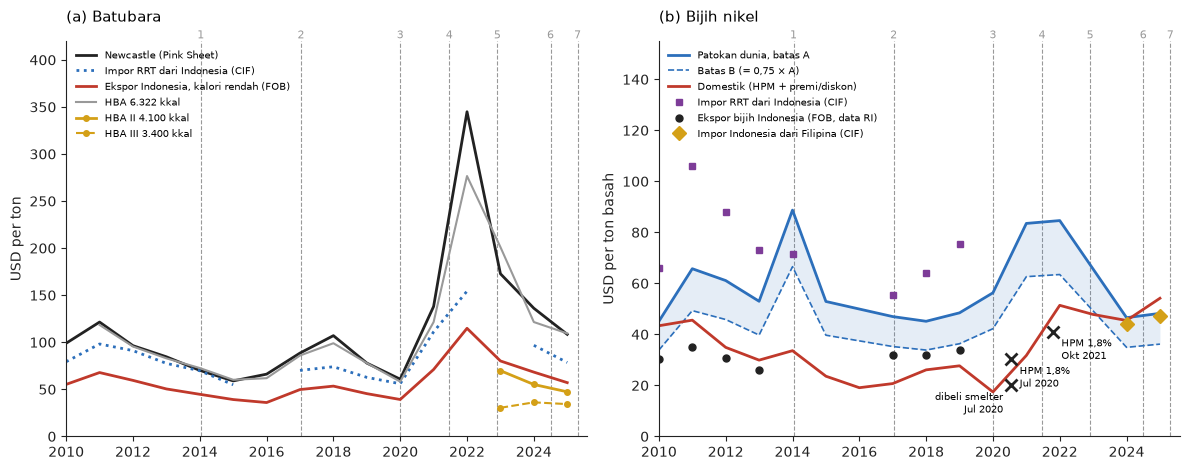

       hpm  domestik  limonit  dunia  dunia_B  bb_fob  sulfur    hba  hba_1  \
2019  27.7      27.7     14.1   48.4     36.3    45.4   123.5   77.9    NaN   
2020  27.4      17.4     14.0   56.3     42.2    39.2    83.4   58.2    NaN   
2021  36.7      31.7     18.7   83.5     62.6    71.1   233.6  121.5    NaN   
2022  51.4      51.4     26.2   84.6     63.5   114.8   297.5  276.6    NaN   
2023  42.8      47.8     26.8   65.6     49.2    80.1   142.2  201.1  102.5   
2024  33.4      45.4     22.0   46.5     34.9    68.3   132.6  121.5   86.6   
2025  30.2      54.2     20.4   48.2     36.2    57.1   300.2  109.4   73.4   

      hba_2  hba_3  
2019    NaN    NaN  
2020    NaN    NaN  
2021    NaN    NaN  
2022    NaN    NaN  
2023   69.8   30.4  
2024   55.2   36.2  
2025   47.4   34.3  


In [4]:
h = pd.read_csv("harga.csv").set_index("tahun")

def nilai_satuan(df, val="primaryValue", wgt="netWgt"):
    g = df.groupby(df.columns[0])[[val, wgt]].sum()
    return (g[val] / g[wgt] * 1000).replace([np.inf, 0], np.nan)

# batubara: harga FOB ekspor batubara kalori rendah Indonesia (HS 270119) dan CIF impor RRT dari Indonesia
cb = pd.read_csv("comtrade_coal.csv", dtype={"cmdCode": str})
h["bb_fob"] = nilai_satuan(cb.query("reporterCode == 360 & cmdCode == '270119'")[["period", "primaryValue", "netWgt"]])
h["bb_cif_rrt"] = nilai_satuan(cb.query("reporterCode == 156 & cmdCode == '2701'")[["period", "primaryValue", "netWgt"]])
h.loc[[2016, 2023], "bb_cif_rrt"] = np.nan      # berat janggal

# belerang dan bijih impor: data ekspor-impor BPS; ferokrom: Comtrade
bps = pd.read_csv("bps_impor.csv", dtype={"hs": str})
h["sulfur"] = nilai_satuan(bps.query("hs == '25030000'")[["tahun", "nilai", "berat"]], "nilai", "berat")
imp_bijih = bps.query("hs == '26040000'").groupby("tahun")[["nilai", "berat"]].sum().reindex(h.index, fill_value=0)
imp = ct.query("job == 'idn_m_input' & partnerCode == 0")[["period", "cmdCode", "primaryValue", "netWgt"]]
h["fecr"] = nilai_satuan(imp.query("cmdCode == '720241'").drop(columns="cmdCode"))

# bijih: impor RRT dari Filipina (patokan dunia) dan dari Indonesia (cermin)
bj = ct.query("job == 'chn_m_ore'")[["period", "partnerCode", "primaryValue", "netWgt"]]
h["cif_ph"] = nilai_satuan(bj.query("partnerCode == 608").drop(columns="partnerCode"))
h["cif_idn"] = nilai_satuan(bj.query("partnerCode == 360").drop(columns="partnerCode"))
h.loc[[2016, 2023], "cif_ph"] = np.nan          # berat 2016 kosong, berat 2023 janggal
h["cif_ph"] = h.cif_ph.interpolate()

air, ongkir = 0.35, 10

def hpm_lama(kadar, lme):
    # HPM bijih nikel sebelum 2026: CF 17% pada kadar 1,6%, berubah 1 poin per 0,1% kadar
    cf = 0.17 + (kadar - 0.016) / 0.001 * 0.01
    return kadar * cf * lme * (1 - air)

def harga_dunia(kadar_ph=0.014, kadar=0.017):
    return h.cif_ph / kadar_ph * kadar - ongkir

# HBA batubara resmi ESDM
esdm = pd.read_csv("harga_hba.csv", parse_dates=["tanggal"])
esdm_th = esdm.pivot_table(index=esdm.tanggal.dt.year, columns="seri", values="nilai")

premi = pd.Series({2020: -10, 2021: -5, 2023: 5, 2024: 12, 2025: 24}).reindex(h.index, fill_value=0)
hb = pd.DataFrame(index=h.index)
hb["hpm"] = hpm_lama(0.017, h.nikel)
hb["domestik"] = hb.hpm + premi                                    # saprolit 1,7%
hb["limonit"] = hpm_lama(0.012, h.nikel) + (h.index >= 2023) * 5   # limonit 1,2%
hb["dunia"] = harga_dunia()                                        # batas A
hb["dunia_B"] = 0.75 * hb.dunia                                    # batas B

# cermin: harga bijih Indonesia di RRT (kadar < 1,7%, anggap 1,6%) relatif terhadap bijih Filipina
cermin = ((h.cif_idn - ongkir) / 0.016) / (h.cif_ph / 0.014)
fob_ri = nilai_satuan(eks.query("hs == '2604'")[["tahun", "primaryValue", "netWgt"]])
print("Rasio harga per satuan Ni, bijih Indonesia di RRT vs bijih Filipina, 2017-19:",
      cermin.loc[2017:2019].round(2).to_dict())
print("Rasio FOB ekspor RI (data RI) / CIF RRT dari RI:",
      (fob_ri / h.cif_idn).reindex([2010, 2011, 2012, 2013, 2014, 2017, 2018, 2019]).round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(h.index, h.batubara, color=ink, lw=2, label="Newcastle (Pink Sheet)")
ax[0].plot(h.index, h.bb_cif_rrt, color=biru, lw=2, ls=":", label="Impor RRT dari Indonesia (CIF)")
ax[0].plot(h.index, h.bb_fob, color=merah, lw=2, label="Ekspor Indonesia, kalori rendah (FOB)")
hba_th = esdm_th.loc[:2025]
ax[0].plot(hba_th.index, hba_th.hba, color=abu, lw=1.5, label="HBA 6.322 kkal")
ax[0].plot(hba_th.index, hba_th.hba_2, color=emas, lw=2, marker="o", ms=4, label="HBA II 4.100 kkal")
ax[0].plot(hba_th.index, hba_th.hba_3, color=emas, lw=1.5, ls="--", marker="o", ms=4, label="HBA III 3.400 kkal")
ax[0].set_ylabel("USD per ton")
ax[0].set_title("(a) Batubara", loc="left", fontsize=11, pad=14)
yy = hb.loc[2010:2025]
ax[1].fill_between(yy.index, yy.dunia_B, yy.dunia, color=biru, alpha=0.12, lw=0)
ax[1].plot(yy.index, yy.dunia, color=biru, lw=2, label="Patokan dunia, batas A")
ax[1].plot(yy.index, yy.dunia_B, color=biru, lw=1.2, ls="--", label="Batas B (= 0,75 × A)")
ax[1].plot(yy.index, yy.domestik, color=merah, lw=2, label="Domestik (HPM + premi/diskon)")
cermin_tahun = [2010, 2011, 2012, 2013, 2014, 2017, 2018, 2019]
ax[1].plot(cermin_tahun, h.cif_idn.loc[cermin_tahun], "s", color=ungu, ms=5,
           label="Impor RRT dari Indonesia (CIF)")
fob_tahun = [y for y in [2010, 2011, 2012, 2013, 2017, 2018, 2019] if y in fob_ri.index]
ax[1].plot(fob_tahun, fob_ri.loc[fob_tahun], "o", color=ink, ms=5, label="Ekspor bijih Indonesia (FOB, data RI)")
ib = (imp_bijih.nilai / imp_bijih.berat * 1000).loc[2024:2025]
ax[1].plot(ib.index, ib, "D", color=emas, ms=7, label="Impor Indonesia dari Filipina (CIF)")
titik = [(2020.55, 30.15, "HPM 1,8%\nJul 2020", 6, "left"), (2020.55, 20, "dibeli smelter\nJul 2020", -6, "right"),
         (2021.8, 41, "HPM 1,8%\nOkt 2021", 6, "left")]
for x, y, lab, dx, ha in titik:
    ax[1].plot(x, y, "x", color=ink, ms=8, mew=2)
    ax[1].annotate(lab, (x, y), xytext=(dx, -4), textcoords="offset points", fontsize=7.5, va="top", ha=ha)
ax[1].set_ylabel("USD per ton basah")
ax[1].set_title("(b) Bijih nikel", loc="left", fontsize=11, pad=14)
for a in ax:
    a.set_xlim(2010, 2025.6)
    garis_peristiwa(a)
    a.legend(frameon=False, fontsize=7.5, loc="upper left")
ax[0].set_ylim(0, 420)
ax[1].set_ylim(0, 155)
fig.tight_layout()
plt.show()
print(pd.concat([hb, h[["bb_fob", "sulfur"]], esdm_th[["hba", "hba_1", "hba_2", "hba_3"]]], axis=1).loc[2019:2025].round(1))

Untuk batubara, harga ekspor kalori rendah Indonesia biasanya sekitar setengah sampai dua pertiga harga Newcastle, dan selisihnya dengan harga CIF di Tiongkok kurang lebih seukuran ongkos kapal. Jadi data batubara terlihat jauh lebih "sehat" daripada data bijih nikel. Pengecualiannya 2022: Newcastle melonjak ke USD345, tapi batubara kalori rendah Indonesia cuma sekitar USD115. HBA utama bergerak mirip Newcastle. HBA II (USD47–70 di 2023–2025) sedikit di bawah harga FOB yang saya pakai (USD57–80), jadi kalau batubara smelter sebenarnya setara HBA II, $E_t$ di model saya terlalu besar sekitar USD0,5–0,7 miliar per tahun. Dampaknya ke kesimpulan relatif kecil (lihat Tabel 4).

Untuk bijih nikel, antara 2020 dan 2022 harga domestik jauh di bawah harga dunia. Di 2020, misalnya, bijih domestik sekitar USD17 per ton (HPM dikurangi diskon), sedangkan batas A sekitar USD56 dan batas B sekitar USD42. Kalau dikalikan volume bijih yang masuk ke smelter RKEF, selisih ini setara dengan **transfer dari penambang ke smelter sekitar USD10 miliar (batas A) atau USD5 miliar (batas B) selama 2020–2022**. Ini sejalan dengan temuan [Kee & Xie (2025, Bank Dunia)](https://thedocs.worldbank.org/en/doc/6c4802573b0952b66e1106612422f12a-0050012025/related/4A-SlidesIndonesiaExportBanNickel.pdf) bahwa larangan ekspor menekan harga nikel domestik lewat monopsoni smelter. Selisih harga sebesar ini juga memberi insentif untuk menyelundup. Data Tiongkok masih mencatat impor bijih **dari Indonesia** sebanyak 3,4 juta ton (2020), 0,8 juta ton (2021), 1,1 juta ton (2022), dan 0,3 juta ton (2023), padahal ekspornya dilarang.

Lalu ceritanya berbalik. Sejak 2024 harga domestik malah **di atas** batas A. Ini terjadi karena kuota produksi tambang (RKAB) diperketat dan kapasitas smelter terus bertambah, sehingga bijih jadi rebutan. Indonesia, negara yang melarang ekspor bijih, sekarang malah **mengimpor** bijih nikel dari Filipina: menurut data BPS, 10,5 juta ton (USD460 juta) di 2024 dan 15,8 juta ton (USD747 juta) di 2025, dengan harga sekitar USD44–47 per ton, hampir sama dengan harga yang dibayar Tiongkok untuk bijih Filipina.

## Isi satu ton nikel

Sekarang kita bongkar isi produk hilirnya. Saya mengukur semua produk dalam **ton nikel yang dikandung** (_contained nickel_), yaitu berat ekspor dikali kadar nikel. Kadar yang saya pakai adalah hitungan kasar: feronikel/NPI 11,5% ([Nickel Industries](https://announcements.asx.com.au/asxpdf/20260223/pdf/06wm4x116x1lxg.pdf) melaporkan 11,8% di 2025), matte 72%, MHP 23% (basis basah), nikel sulfat 22%, nikel tidak tempa 99,8%, dan baja nirkarat rata-rata 6% (campuran seri 300 dengan nikel 8% dan seri 200/400 yang lebih rendah). Hasilnya sekitar 2,4 juta ton Ni di 2025.

Ada dua jalur produksi utama. **RKEF** (_rotary kiln–electric furnace_) melebur bijih saprolit menjadi NPI/feronikel. Sebagian NPI lalu dijadikan matte atau baja nirkarat. **HPAL** (_high pressure acid leach_) melarutkan bijih limonit dengan asam sulfat menjadi MHP, bahan baku baterai.

Tabel 1 merangkum koefisien input per ton nikel. Sebagian besar angkanya adalah perkiraan teknis dari literatur dan laporan perusahaan, bukan data yang terukur langsung. Tolong baca dengan hati-hati.

| Komponen per ton Ni | RKEF (NPI/feronikel) | HPAL (MHP) | Sumber |
|---|---|---|---|
| Bijih | 101 t basah (saprolit 1,7%, air 35%, perolehan 90%) | 138 t basah (limonit 1,2%, perolehan 93%) | dihitung sendiri |
| Listrik | 35 MWh ≈ 21 t batubara | 15,6 MWh ≈ 9,4 t batubara | [AEER (2026)](https://www.aeer.or.id/wp-content/uploads/2026/01/AEER-Report-EN-From-Captives-to-Green-Grids.pdf); [Ember](https://ember-energy.org/app/uploads/2025/10/Policy-paper-From-Captive-Coal-to-Green-Nickel_-Securing-Indonesias-Future-Competitiveness-2.pdf) |
| Reduktan & bahan bakar kiln | ±8 t batubara | ±1 t batubara | tebakan kasar |
| Belerang (impor) | – | 11 t | [Mysteel](https://www.mysteel.net/analysis/5122400-nickel-prices-to-rise-further-as-mhp-supply-tightening-moves-from-expectation-to-reality); [SMM](https://news.metal.com/newscontent/103660342/[SMM-Analysis]-Impact-of-Sulfur-Price-Changes-on-Nickel-Price) |
| Batu kapur | – | 30 t × USD10 | tebakan |
| Upah pekerja Indonesia | USD550 | USD550 | perkiraan dari IMIP, lihat teks |
| Upah TKA | USD400 | USD400 | idem |
| Biaya kas lain | USD1.990 (dikalibrasi) | USD500 | [Nickel Industries](https://announcements.asx.com.au/asxpdf/20260223/pdf/06wm4x116x1lxg.pdf) |
| Tambahan untuk matte | konverter USD1.000 + 1 t batubara | – | [SMM](https://news.metal.com/newscontent/101672434-spoiler-china-nickel-industry-chain-annual-report-2021-2025) |

Ada beberapa asumsi lain:
- **Harga input.** Batubara dinilai dengan harga ekspor batubara kalori rendah Indonesia dari Gambar 3. Belerang memakai harga impor menurut data ekspor-impor BPS, yaitu nilai dibagi berat, sekitar USD83 per ton di 2020, USD298 di 2022, dan USD300 di 2025. Ferokrom memakai harga impor dari Comtrade.
- **Baja nirkarat.** Per ton baja saya hitung 0,06 t Ni (lewat NPI, dihitung di jalur RKEF), 0,33 t ferokrom (sebagian besar krom memang diimpor dari Afrika Selatan, baik sebagai ferokrom maupun bijih krom), 0,6 t batubara, upah USD60 (USD35 WNI, USD25 TKA), dan biaya lain USD120.
- **Upah.** Saya perkirakan dari IMIP: sekitar 110 ribu pekerja Indonesia (termasuk kontraktor) dengan penghasilan sekitar Rp6,5 juta per bulan, dan 16 ribu TKA ([Rest of World](https://restofworld.org/2025/nickel-ev-batteries-indonesia-layoffs/)). Dengan anggapan IMIP memproduksi sekitar 1 juta ton Ni, ini setara sekitar USD550 per ton Ni untuk upah WNI dan USD400 untuk TKA (sekitar USD25 ribu per orang per tahun).
- **Biaya kas lain RKEF** (elektroda, pemeliharaan, jasa, dan lain-lain) saya kalibrasi supaya total biaya kas 2025 sama dengan yang dilaporkan [Nickel Industries](https://announcements.asx.com.au/asxpdf/20260223/pdf/06wm4x116x1lxg.pdf), yaitu USD10.042 per ton Ni.

In [5]:
KADAR = {"720260": 0.115, "750110": 0.72, "750120": 0.23, "7502": 0.998, "283324": 0.22,
         "7218": 0.06, "7219": 0.06, "7220": 0.06}
JALUR = {"720260": "RKEF", "750110": "RKEF", "750120": "HPAL", "7502": "HPAL", "283324": "HPAL"}
BAJA = ["7218", "7219", "7220"]

bijih_rkef = 1 / (0.017 * (1 - air) * 0.90)    # ton basah bijih per ton Ni
bijih_hpal = 1 / (0.012 * (1 - air) * 0.93)
bb_rkef, bb_matte, bb_hpal = 35 * 0.6 + 8, 1.0, 15.6 * 0.6 + 1
s_hpal, kapur_hpal, lain_hpal, konverter = 11.0, 300, 500, 1000
upah_dom, upah_tka = 550, 400
fecr_ss, bb_ss, upah_dom_ss, upah_tka_ss, lain_ss = 0.33, 0.6, 35, 25, 120

# biaya lain RKEF dikalibrasi supaya biaya kas 2025 = USD10.042/t Ni (Nickel Industries)
lain_rkef = 10042 - (bijih_rkef * hb.loc[2025, "domestik"] + bb_rkef * h.loc[2025, "bb_fob"]
                     + upah_dom + upah_tka)
print(f"bijih per t Ni: RKEF {bijih_rkef:.0f} t, HPAL {bijih_hpal:.0f} t; biaya lain RKEF USD{lain_rkef:,.0f}/t Ni")

bijih per t Ni: RKEF 101 t, HPAL 138 t; biaya lain RKEF USD1,990/t Ni


Dengan koefisien itu, nilai ekspor produk hilir setiap tahun bisa dipecah menjadi:

$$
X_t = B_t + E_t + M_t + L_t + W^{d}_t + W^{f}_t + R_t + \Pi_t
$$

di mana:
- $X_t$ adalah nilai ekspor produk hilir di tahun $t$;
- $B_t$ adalah pembayaran bijih ke penambang **dalam negeri** dengan harga domestik, termasuk royalti bijih;
- $E_t$ adalah batubara untuk listrik dan reduktan;
- $M_t$ adalah input impor: belerang, ferokrom, dan bijih yang diimpor dari Filipina, yang uangnya jelas lari ke penambang Filipina;
- $L_t$ adalah biaya kas lain;
- $W^{d}_t$ dan $W^{f}_t$ adalah upah pekerja Indonesia dan TKA;
- $R_t$ adalah royalti atas produk olahan;
- $\Pi_t$ adalah sisanya, yaitu **pendapatan modal**: penyusutan, bunga, laba, dan pajak penghasilan badan. Pajak badan sebagian besar nol karena _tax holiday_ 5–20 tahun.

Royalti saya hitung dengan tarif resmi (bijih 10%, naik ke 14–19% sejak April 2025; NPI 5%, naik ke 5–7%; MHP sekitar 2%), lalu dikalibrasi supaya totalnya sama dengan penerimaan royalti nikel yang dilaporkan, Rp11,63 T (2024) dan Rp19 T (2025). Faktor kalibrasinya 0,40. Artinya, royalti yang benar-benar dibayar jauh di bawah tarif dikali nilai ekspor, karena basis royalti adalah HPM, bukan harga ekspor.

Yang **tertahan** di Indonesia:

$$
D_t = B_t + L_t + W^{d}_t + R_t + (1-\theta)\,\Pi_t
$$

di mana $\theta$ adalah porsi kepemilikan asing atas smelter. Saya pakai $\theta$ = 0,75 berdasarkan [C4ADS (2025)](https://c4ads.org/commentary/refining-power/), yang menemukan lebih dari 75% kapasitas smelter nikel Indonesia dimiliki perusahaan Tiongkok pada level _beneficial ownership_. Batubara ($E_t$) sengaja **tidak** saya masukkan ke $D_t$. Batubara memang ditambang di Indonesia, tapi kalau tidak dibakar di smelter ia bisa diekspor dengan harga dunia, jadi ia bukan tambahan dari hilirisasi. Sebaliknya, biaya kas lain ($L_t$) saya anggap seluruhnya belanja domestik, yaitu ke kontraktor, tongkang, pelabuhan, dan pemasok lokal yang kemungkinan besar tidak akan ada tanpa smelter. Anggapan ini murah hati, karena sebagian isinya barang impor seperti elektroda dan suku cadang. Tabel 4 menguji anggapan ini.

Sebagai pembanding, nilai ekspor bijih kalau larangan tidak ada:

$$
C_t = Q^{sap}_t \, p^{A \text{ atau } B}_t + Q^{lim}_t \, p^{lim}_t
$$

di mana $Q^{sap}_t$ adalah volume bijih saprolit **domestik** yang terkandung dalam ekspor produk hilir (bijih impor tidak dihitung), $Q^{lim}_t$ adalah volume limonit, dan $p^{lim}_t$ adalah harga limonit domestik. Untuk limonit saya tidak memakai harga dunia, karena dulu limonit nyaris tidak laku diekspor. **Manfaat bersih** larangan ekspor adalah $G_t = D_t - C_t$.

Satu asumsi penting: di $C_t$ volume nikelnya sama dengan yang sekarang diekspor sebagai produk hilir. Ini asumsi yang "murah hati" untuk skenario tanpa larangan, karena belum tentu pasar bijih dunia mau menyerap bijih sebanyak itu. Diskon di batas B dimaksudkan untuk menangkap sebagian masalah ini. Tabel 2 berisi hasilnya dalam miliar dolar (kecuali baris pertama, ribu ton Ni).

In [6]:
roy_bijih = {t: 0.10 if t >= 2020 else 0.05 for t in range(2015, 2026)} | {2025: 0.10 * 0.32 + 0.16 * 0.68}
roy_rkef = {t: 0.05 for t in range(2015, 2026)} | {2025: 0.05 * 0.32 + 0.06 * 0.68}
roy_hpal = {t: 0.02 for t in range(2015, 2026)} | {2025: 0.02 * 0.32 + 0.035 * 0.68}
roy_lapor = pd.Series({2024: 11.63e12, 2025: 19e12}) / h.kurs.loc[[2024, 2025]]   # USD

def dekomposisi(theta=0.75, kadar_ph=0.014, l_dom=1.0):
    # l_dom: porsi biaya kas lain (L) yang dianggap belanja domestik dan ikut tertahan
    dunia = harga_dunia(kadar_ph)
    rows = []
    for t, g in eks[eks.hs.isin(KADAR) & eks.tahun.between(2015, 2025)].groupby("tahun"):
        g = g.assign(ni=g.netWgt / 1000 * g.hs.map(KADAR), jalur=g.hs.map(JALUR))
        baja = g[g.hs.isin(BAJA)]
        ni_rkef = g.query("jalur == 'RKEF'").ni.sum() + baja.ni.sum()
        ni_matte = g.query("hs == '750110'").ni.sum()
        ni_hpal = g.query("jalur == 'HPAL'").ni.sum()
        t_baja = baja.netWgt.sum() / 1000
        pb = h.loc[t, "bb_fob"]
        # bijih impor (Filipina) menggantikan sebagian saprolit domestik, disetarakan ke kadar 1,7%
        sap_dom = ni_rkef * bijih_rkef - imp_bijih.loc[t, "berat"] / 1000 * 0.014 / 0.017
        d = dict(tahun=t, X=g.primaryValue.sum(), ni_rkef=ni_rkef, ni_hpal=ni_hpal)
        d["B"] = sap_dom * hb.loc[t, "domestik"] + ni_hpal * bijih_hpal * hb.loc[t, "limonit"]
        d["bb_ton"] = ni_rkef * bb_rkef + ni_matte * bb_matte + ni_hpal * bb_hpal + t_baja * bb_ss
        d["E"] = d["bb_ton"] * pb
        d["M"] = (ni_hpal * s_hpal * h.loc[t, "sulfur"] + t_baja * fecr_ss * h.loc[t, "fecr"]
                  + imp_bijih.loc[t, "nilai"])
        d["L"] = (ni_rkef * lain_rkef + ni_matte * konverter + ni_hpal * (lain_hpal + kapur_hpal)
                  + t_baja * lain_ss)
        d["Wd"] = (ni_rkef + ni_hpal) * upah_dom + t_baja * upah_dom_ss
        d["Wf"] = (ni_rkef + ni_hpal) * upah_tka + t_baja * upah_tka_ss
        d["Rb"] = roy_bijih[t] * d["B"]
        d["R"] = (roy_rkef[t] * g.query("jalur == 'RKEF'").primaryValue.sum()
                  + roy_hpal[t] * g.query("jalur == 'HPAL'").primaryValue.sum())
        d["C_A"] = sap_dom * dunia.loc[t] + ni_hpal * bijih_hpal * hb.loc[t, "limonit"]
        d["C_B"] = sap_dom * 0.75 * dunia.loc[t] + ni_hpal * bijih_hpal * hb.loc[t, "limonit"]
        d["transfer_A"] = max(dunia.loc[t] - hb.loc[t, "domestik"], 0) * sap_dom
        d["transfer_B"] = max(0.75 * dunia.loc[t] - hb.loc[t, "domestik"], 0) * sap_dom
        rows.append(d)
    df = pd.DataFrame(rows).set_index("tahun")
    k = (roy_lapor / (df.Rb + df.R).loc[roy_lapor.index]).mean()   # kalibrasi royalti
    df[["Rb", "R"]] *= k
    df["Pi"] = df.X - df[["B", "E", "M", "L", "Wd", "Wf", "R"]].sum(axis=1)
    df["Pi_f"], df["Pi_d"] = theta * df.Pi, (1 - theta) * df.Pi
    df["D"] = df.B + df.Wd + df.R + df.Pi_d + l_dom * df.L
    df["G_A"], df["G_B"] = df.D - df.C_A, df.D - df.C_B
    df.attrs["k"] = k
    return df

df = dekomposisi()
print(f"faktor kalibrasi royalti k = {df.attrs['k']:.2f}")
print("Transfer penambang ke smelter 2020-2022 (miliar USD): A =",
      round(df.loc[2020:2022, "transfer_A"].sum() / 1e9, 1), ", B =",
      round(df.loc[2020:2022, "transfer_B"].sum() / 1e9, 1))
print("Batubara untuk produk ekspor (juta t):", (df.bb_ton.loc[[2019, 2025]] / 1e6).round(1).to_dict())
tabel = df.loc[2017:].drop(columns=["ni_rkef", "ni_hpal", "bb_ton", "transfer_A", "transfer_B"]) / 1e9
tabel.insert(0, "Ni (ribu t)", (df.ni_rkef + df.ni_hpal).loc[2017:] / 1e3)
tabel.round(1).T

faktor kalibrasi royalti k = 0.40
Transfer penambang ke smelter 2020-2022 (miliar USD): A = 9.9 , B = 5.1
Batubara untuk produk ekspor (juta t): {2019: 12.6, 2025: 62.3}


tahun,2017,2018,2019,2020,2021,2022,2023,2024,2025
Ni (ribu t),227.2,282.0,384.3,571.2,767.7,1247.5,1697.6,2062.7,2426.4
X,3.0,5.3,7.1,10.2,18.7,30.4,30.7,30.8,34.5
B,0.5,0.7,1.1,1.0,2.4,6.3,7.9,8.4,10.9
E,0.4,0.5,0.6,0.7,1.8,4.2,3.8,3.7,3.6
M,0.2,0.7,0.8,0.9,2.1,2.6,2.0,3.0,4.3
L,0.6,0.9,1.1,1.6,2.1,3.1,3.8,4.4,4.9
Wd,0.1,0.2,0.3,0.4,0.6,0.8,1.1,1.3,1.5
Wf,0.1,0.2,0.2,0.3,0.4,0.6,0.8,0.9,1.1
Rb,0.0,0.0,0.0,0.0,0.1,0.3,0.3,0.3,0.6
R,0.0,0.0,0.1,0.1,0.2,0.4,0.4,0.4,0.5


Gambar 4 memvisualisasikan Tabel 2 untuk 2017–2025. Setiap batang adalah nilai ekspor produk hilir (miliar USD) yang dipecah menurut komponennya. Garis hitam adalah yang tertahan di Indonesia ($D_t$). Garis merah putus-putus dan titik-titik adalah kontrafaktual ekspor bijih ($C_t$) batas A dan B. Selama 2017–2019 ekspor bijih masih dibolehkan, jadi perbandingan $D_t$ dengan $C_t$ baru relevan mulai 2020.

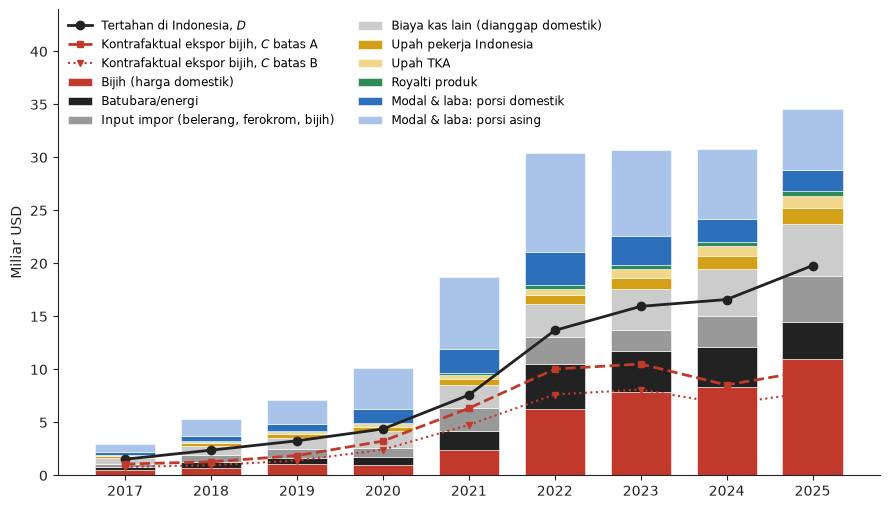

In [7]:
blok = [("B", "Bijih (harga domestik)", merah), ("E", "Batubara/energi", ink),
        ("M", "Input impor (belerang, ferokrom, bijih)", abu), ("L", "Biaya kas lain (dianggap domestik)", "#cccccc"),
        ("Wd", "Upah pekerja Indonesia", emas), ("Wf", "Upah TKA", "#f0d78c"),
        ("R", "Royalti produk", hijau), ("Pi_d", "Modal & laba: porsi domestik", biru),
        ("Pi_f", "Modal & laba: porsi asing", "#a9c4e8")]
yy = df.loc[2017:2025]
fig, ax = plt.subplots(figsize=(9, 5.2))
bawah = np.zeros(len(yy))
for k, lab, c in blok:
    ax.bar(yy.index, yy[k] / 1e9, bottom=bawah, color=c, width=0.7, label=lab, edgecolor="white", lw=0.4)
    bawah += yy[k].values / 1e9
ax.plot(yy.index, yy.D / 1e9, color=ink, marker="o", lw=2, zorder=5, label="Tertahan di Indonesia, $D$")
ax.plot(yy.index, yy.C_A / 1e9, color=merah, lw=2, ls="--", marker="s", ms=5, zorder=5,
        label="Kontrafaktual ekspor bijih, $C$ batas A")
ax.plot(yy.index, yy.C_B / 1e9, color=merah, lw=1.5, ls=":", marker="v", ms=5, zorder=5,
        label="Kontrafaktual ekspor bijih, $C$ batas B")
ax.set_ylim(0, 44)
ax.set_ylabel("Miliar USD")
ax.set_xticks(yy.index)
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

Batang yang tinggi itu ternyata sebagian besar bukan nilai tambah hilirisasi. Bagian merah di bawah adalah bijih, yang toh akan ada juga tanpa larangan. Bagian hitam adalah batubara, dan abu-abu tua adalah input impor. Abu-abu muda adalah biaya kas lain, yang saya anggap seluruhnya belanja domestik. Biru muda di atas, yang paling besar di antara komponen nilai tambah, adalah pendapatan modal yang mengalir ke pemilik asing.

Apakah angka-angka ini masuk akal? Satu cara mengeceknya adalah dengan PDB. Kalau $X_t$ dikurangi input antara ($B_t + E_t + M_t + L_t$), hasilnya seharusnya kira-kira sama dengan NTB industri logam dasar di provinsi nikel menurut harga berlaku. Tabel 3 membandingkan keduanya dalam miliar dolar: NTB logam dasar nasional dan NTB logam dasar Sulteng + Malut (BPS, harga berlaku, dikonversi dengan kurs tahunan dari FRED), dan "nilai tambah" versi model.

In [8]:
pdb_h = pd.read_csv("pdb_sektor.csv").query("periode == 'Tahunan' & harga == 'ADHB'")
ld = pdb_h.query("sektor == 'Industri Logam Dasar'").set_index("tahun").nilai * 1e9 / h.kurs
pv = pd.read_csv("pdrb_nikel.csv").query("harga == 'ADHB' & sektor == 'Industri Logam Dasar'")
ld_prov = pv.groupby("tahun").nilai.sum() * 1e9 / h.kurs
nt_model = df.X - df[["B", "E", "M", "L"]].sum(axis=1)
cek = pd.DataFrame({"NTB logam dasar Indonesia": ld, "NTB logam dasar Sulteng+Malut": ld_prov,
                    "Model: X − input antara": nt_model}).loc[2019:2025] / 1e9
cek.round(1)

,NTB logam dasar Indonesia,NTB logam dasar Sulteng+Malut,Model: X − input antara
tahun,,,
2019,8.2,2.1,3.5
2020,8.3,3.1,6.0
2021,9.6,5.5,10.2
2022,11.3,8.6,14.3
2023,12.9,9.5,13.1
2024,14.3,10.0,11.3
2025,16.6,11.5,10.8


Untuk 2023–2025, model saya (USD11–13 miliar) cukup dekat dengan NTB logam dasar Sulteng + Malut (USD10–12 miliar). Itu pun Sulawesi Tenggara (Konawe, Morosi) belum masuk, karena BPS provinsinya tidak menyajikan rincian per sub-lapangan usaha. Di 2022 model saya lebih tinggi (USD14 miliar lawan USD9 miliar), mungkin karena harga nikel 2022 melonjak tajam, sementara biaya di model saya banyak yang dibuat konstan. Angka nasional lebih besar karena juga mencakup baja, aluminium, dan smelter tembaga. Jadi besarannya masuk akal, meski tiap komponennya masih kasar.

Satu hal yang perlu dicatat: NTB di PDB dihitung berdasarkan **wilayah**, tidak peduli siapa pemiliknya. Laba smelter milik investor Tiongkok di Morowali tetap tercatat sebagai PDB Indonesia. Yang tidak ikut adalah PNB (pendapatan nasional bruto). Inilah kenapa pertumbuhan PDB Sulawesi Tengah dan Maluku Utara yang dua digit belum tentu terasa sebanding di kantong warganya.

## Siapa yang dapat?

In [9]:
porsi = (df.loc[2025, [k for k, _, _ in blok]] / df.loc[2025, "X"] * 100).round(1)
porsi.index = [lab for _, lab, _ in blok]
print("Dari setiap USD100 ekspor produk hilir nikel tahun 2025:")
print(porsi.to_string())
nt_hilir = (df.L + df.Wd + df.R + df.Pi_d) / df.X * 100
print("\nNilai tambah hilirisasi yang tertahan (L + Wd + R + Pi_d), % ekspor:")
print(nt_hilir.loc[2019:].round(1).to_string())

Dari setiap USD100 ekspor produk hilir nikel tahun 2025:
Bijih (harga domestik)                     31.7
Batubara/energi                            10.3
Input impor (belerang, ferokrom, bijih)    12.6
Biaya kas lain (dianggap domestik)         14.2
Upah pekerja Indonesia                      4.3
Upah TKA                                    3.1
Royalti produk                              1.5
Modal & laba: porsi domestik                5.6
Modal & laba: porsi asing                  16.7

Nilai tambah hilirisasi yang tertahan (L + Wd + R + Pi_d), % ekspor:
tahun
2019    31.0
2020    33.2
2021    27.5
2022    24.4
2023    26.2
2024    26.8
2025    25.6


Dari setiap USD100 ekspor produk hilir nikel di 2025, sekitar USD32 adalah bijih domestik, USD10 batubara, USD13 input impor (termasuk bijih Filipina), dan USD14 biaya kas lain (yang saya anggap belanja domestik). Upah pekerja Indonesia cuma sekitar USD4, royalti produk sekitar USD1,5, dan porsi domestik dari pendapatan modal sekitar USD6. Pendapatan modal yang mengalir ke pemilik asing sekitar USD17, ditambah USD3 upah TKA.

Jadi nilai tambah **dari pengolahan** yang tertahan di Indonesia ($L_t + W^d_t + R_t + (1-\theta)\Pi_t$) sekitar **24–33% dari nilai ekspor**, dan cenderung turun dari tahun ke tahun. Lebih dari separuhnya adalah biaya kas lain. Kalau biaya kas lain ternyata banyak yang impor, porsinya bisa turun sampai 11–18%. Klaim Faisal Basri (alm.) bahwa 90% nilai tambah lari ke Tiongkok mungkin berlebihan. Tapi kalau "nilai tambah" yang dimaksud adalah semua yang di atas bijih, porsi yang disumberkan dari luar (pendapatan modal asing, upah TKA, dan input impor) memang besar.

Apakah aliran laba ke luar negeri kelihatan di neraca pembayaran? Gambar 5 menunjukkan pendapatan ekuitas investasi langsung (dividen dan laba ditahan) yang dibayarkan Indonesia ke luar negeri, miliar USD, 2010–2025, dari statistik neraca pembayaran IMF (garis biru). Garis merah putus-putus adalah porsi asing dari pendapatan modal hilirisasi nikel menurut model ($\theta\,\Pi_t$).

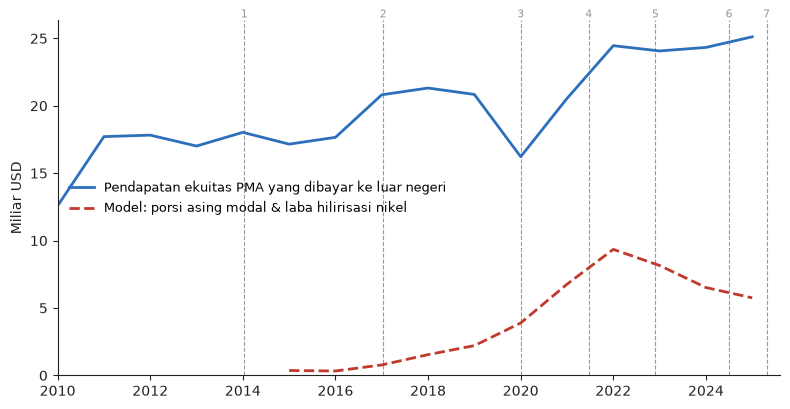

TIME_PERIOD
2017    20.8
2018    21.3
2019    20.8
2022    24.5
2023    24.1
2024    24.3
2025    25.1


In [10]:
bop = pd.read_csv("bop_income.csv").set_index("TIME_PERIOD")
bop.index = bop.index.astype(int)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(bop.index, bop.D_F5_D4S / 1e9, color=biru, lw=2,
        label="Pendapatan ekuitas PMA yang dibayar ke luar negeri")
ax.plot(df.index, df.Pi_f / 1e9, color=merah, lw=2, ls="--",
        label="Model: porsi asing modal & laba hilirisasi nikel")
ax.set_xlim(2010, 2025.6)
ax.set_ylim(0)
garis_peristiwa(ax)
ax.set_ylabel("Miliar USD")
ax.legend(frameon=False, fontsize=9, loc="center left")
fig.tight_layout()
plt.show()
print((bop.D_F5_D4S / 1e9).loc[[2017, 2018, 2019, 2022, 2023, 2024, 2025]].round(1).to_string())

Pendapatan ekuitas PMA yang dibayar ke luar negeri memang naik, dari sekitar USD21 miliar di 2017–2019 ke USD24–25 miliar di 2022–2025. Tapi kenaikannya (sekitar USD4 miliar) lebih kecil dari porsi asing versi model (USD6–9 miliar per tahun sejak 2021). Ada beberapa kemungkinan penjelasannya:
- $\Pi_t$ di model juga berisi penyusutan, yang bukan laba.
- Bunga pinjaman dari induk perusahaan atau bank Tiongkok dicatat di pos lain neraca pembayaran.
- Komponen biaya di model saya bisa jadi terlalu rendah.
- Yang paling menarik: kalau smelter menjual produknya ke induknya di Tiongkok dengan harga di bawah pasar (_transfer pricing_), laba yang tercatat di Indonesia jadi lebih kecil, tapi nilai ekspornya juga ikut lebih kecil.
- Kenaikan 2022 juga tercampur dengan _windfall_ batubara.

Jadi bukti dari neraca pembayaran ini **konsisten tapi lemah**.

## Jadi, lebih baik ekspor bijih?

Sekarang pertanyaan utamanya: apakah $D_t$ lebih besar dari $C_t$? Tabel 4 menunjukkan manfaat bersih $G_t = D_t - C_t$ (miliar USD) untuk tiga nilai $\theta$ (porsi asing 60%, 75%, dan 90%), dua batas harga bijih, dan, untuk batas A, dua tebakan kadar bijih Filipina yang berbeda (1,3% dan 1,5%) serta batubara yang dinilai dengan HBA II, dan biaya kas lain yang hanya separuh atau sama sekali tidak dianggap belanja domestik.

In [11]:
hasil = pd.DataFrame({theta: dekomposisi(theta).loc[2020:2025, ["G_A", "G_B"]].stack() / 1e9
                      for theta in (0.6, 0.75, 0.9)}).unstack().round(1)
hasil.columns = [f"θ={t}, batas {b[-1]}" for t, b in hasil.columns]
for kp in (0.013, 0.015):
    hasil[f"θ=0.75, batas A, kadar Filipina {kp:.1%}"] = (dekomposisi(0.75, kp).G_A.loc[2020:2025] / 1e9).round(1)

# sensitivitas batubara: dinilai dengan HBA II (4.100 kkal) sejak 2023, biaya lain RKEF dikalibrasi ulang
bb_asli, lain_asli = h.bb_fob.copy(), lain_rkef
h["bb_fob"] = esdm_th.hba_2.reindex(h.index).fillna(bb_asli)
lain_rkef = 10042 - (bijih_rkef * hb.loc[2025, "domestik"] + bb_rkef * h.loc[2025, "bb_fob"] + upah_dom + upah_tka)
d_hba = dekomposisi()
h["bb_fob"], lain_rkef = bb_asli, lain_asli
hasil["θ=0.75, batas A, batubara HBA II"] = (d_hba.G_A.loc[2020:2025] / 1e9).round(1)

# sensitivitas biaya kas lain: hanya separuh atau sama sekali tidak ada L yang belanja domestik
for ld in (0.5, 0.0):
    hasil[f"θ=0.75, batas A, {ld:.0%} L domestik"] = (dekomposisi(l_dom=ld).G_A.loc[2020:2025] / 1e9).round(1)
print("E dengan HBA II dikurangi E dasar (miliar USD):", ((d_hba.E - df.E).loc[2023:2025] / 1e9).round(2).to_dict())

print("Kumulatif 2020-2025, miliar USD:", hasil.sum().round(1).to_dict())
print("Ekspor produk hilir kumulatif 2020-2025, miliar USD:", round(df.loc[2020:2025, "X"].sum() / 1e9, 1))

# tax holiday: seandainya PPh badan 22% dibayar atas laba kena pajak sebesar 40-60% dari Pi
for s in (0.4, 0.6):
    pajak = 0.22 * s * df.Pi.loc[2020:2025]
    print(f"PPh hilang (laba kena pajak {s:.0%} Pi), miliar USD:", (pajak / 1e9).round(1).to_dict(),
          f"| tambahan D = θ x PPh, kumulatif: {0.75 * pajak.sum() / 1e9:.1f}")
hasil

E dengan HBA II dikurangi E dasar (miliar USD): {2023: -0.49, 2024: -0.72, 2025: -0.61}
Kumulatif 2020-2025, miliar USD: {'θ=0.6, batas A': 37.5, 'θ=0.6, batas B': 48.6, 'θ=0.75, batas A': 29.3, 'θ=0.75, batas B': 40.5, 'θ=0.9, batas A': 21.4, 'θ=0.9, batas B': 32.5, 'θ=0.75, batas A, kadar Filipina 1.3%': 25.4, 'θ=0.75, batas A, kadar Filipina 1.5%': 32.8, 'θ=0.75, batas A, batubara HBA II': 31.5, 'θ=0.75, batas A, 50% L domestik': 19.5, 'θ=0.75, batas A, 0% L domestik': 9.6}
Ekspor produk hilir kumulatif 2020-2025, miliar USD: 155.3
PPh hilang (laba kena pajak 40% Pi), miliar USD: {2020: 0.5, 2021: 0.8, 2022: 1.1, 2023: 1.0, 2024: 0.8, 2025: 0.7} | tambahan D = θ x PPh, kumulatif: 3.6
PPh hilang (laba kena pajak 60% Pi), miliar USD: {2020: 0.7, 2021: 1.2, 2022: 1.6, 2023: 1.4, 2024: 1.1, 2025: 1.0} | tambahan D = θ x PPh, kumulatif: 5.3


,"θ=0.6, batas A","θ=0.6, batas B","θ=0.75, batas A","θ=0.75, batas B","θ=0.9, batas A","θ=0.9, batas B","θ=0.75, batas A, kadar Filipina 1.3%","θ=0.75, batas A, kadar Filipina 1.5%","θ=0.75, batas A, batubara HBA II","θ=0.75, batas A, 50% L domestik","θ=0.75, batas A, 0% L domestik"
tahun,,,,,,,,,,,
2020,1.9,2.7,1.1,2.0,0.4,1.2,0.8,1.4,1.3,0.4,-0.4
2021,2.6,4.2,1.2,2.8,-0.1,1.5,0.7,1.7,1.4,0.2,-0.9
2022,5.5,7.9,3.6,6.0,1.8,4.2,2.8,4.4,3.9,2.1,0.6
2023,7.1,9.5,5.4,7.9,3.8,6.2,4.6,6.2,5.9,3.5,1.6
2024,9.4,11.2,8.1,9.9,6.8,8.6,7.4,8.6,8.6,5.9,3.7
2025,11.0,13.1,9.9,11.9,8.7,10.8,9.1,10.5,10.4,7.4,5.0


Jawabannya ternyata: **hilirisasi tetap lebih baik dari ekspor bijih, tapi tambahannya jauh lebih kecil dari yang diklaim**.

- **2020–2021**: dengan harga bijih dunia (batas A) dan $\theta$ = 0,75, manfaat bersih larangan ekspor positif tapi tipis, sekitar 1,1 dan 1,2 miliar dolar, padahal ekspor produk hilirnya 10–19 miliar dolar. Dengan $\theta$ = 0,9, angka 2021 sudah nyaris nol. Di periode ini penambang mensubsidi smelter lewat harga bijih yang ditekan (transfer sekitar USD5–10 miliar selama 2020–2022), dan sebagian besar subsidi itu jatuh ke pemilik modal asing. Teori saya hampir benar di sini, tapi tidak sampai negatif.
- **2022–2025**: manfaat bersihnya membesar, sekitar USD4–10 miliar per tahun di batas A dan USD6–12 miliar di batas B. Tapi lihat dari mana asalnya. Sebagian besar kenaikan ini muncul karena **harga bijih domestik mengejar, lalu melampaui, harga dunia** ketika kuota diperketat dan bijih jadi langka, bukan karena smelter makin efisien. Manfaatnya membesar setelah penambang berhenti mensubsidi smelter.
- Secara kumulatif 2020–2025, manfaat bersihnya sekitar **USD29 miliar (batas A) sampai USD41 miliar (batas B)**, sementara ekspor produk hilir kumulatifnya USD155 miliar. Kalau kadar bijih Filipina sebenarnya 1,3%, angka batas A turun ke sekitar USD25 miliar. Kalau 1,5%, naik ke sekitar USD33 miliar. Kalau batubara dinilai dengan HBA II, angkanya naik sedikit ke USD31,5 miliar. Batubara yang lebih murah tidak mengubah total biaya kas RKEF (dikunci ke laporan Nickel Industries), jadi selisihnya pindah ke biaya kas lain, yang di sini dianggap domestik.
- Yang paling sensitif adalah anggapan soal biaya kas lain ($L_t$). Saya menganggap seluruhnya belanja domestik, dan ini murah hati: sebagian besar isi $L_t$ (elektroda, suku cadang, reagen) diimpor dari Tiongkok, sebagian pekerja kontraktor sudah masuk perkiraan upah $W^d_t$, dan $L_t$ untuk RKEF sendiri adalah sisa kalibrasi, bukan hasil pengukuran. Kalau hanya separuhnya yang domestik, manfaat kumulatif di batas A turun ke sekitar USD20 miliar. Kalau tidak ada sama sekali, tinggal USD10 miliar, dan 2020–2021 jadi negatif (−0,4 dan −0,9 miliar dolar).
- Artinya, tambahan buat Indonesia dibanding skenario ekspor bijih sekitar **19–26%** dari angka ekspor kotor, dan bisa serendah 6% kalau biaya kas lain ternyata kebanyakan impor. Bukan 20 kali lipat.

## 2026: negara mulai menagih sewa bijih nikel

Tahun 2026 ada tiga perubahan sekaligus yang mengubah hitungan di atas. Angka-angka di bagian ini adalah _educated guess_ dari pemberitaan, bukan data resmi, jadi jangan langsung dipercaya. Buat bahan diskusi aja.

**Pertama, kuota tambang (RKAB) dipangkas.** Menurut pemberitaan, kuota bijih 2026 dibahas di kisaran 250–270 juta ton, turun dari sekitar 379 juta ton di 2025 ([Bisnis](https://ekonomi.bisnis.com/read/20260302/44/1957014/pengusaha-wanti-wanti-krisis-bijih-nikel-potensi-defisit-capai-130-juta-ton)). Sampai pertengahan tahun angkanya belum final ([Bisnis](https://ekonomi.bisnis.com/read/20260625/44/1983223/kementerian-esdm-belum-putuskan-besaran-rkab-nikel-2026)). Saya anggap volume nikel yang diolah turun sekitar 3% dari 2025. Kuota yang ketat membuat bijih jadi rebutan, sehingga harga domestik naik dan smelter makin banyak mengimpor bijih dari Filipina.

**Kedua, formula HPM diganti** lewat Kepmen ESDM 144/2026, berlaku mulai [pertengahan April 2026](https://www.mysteel.net/analysis/5119751-newly-revised-nickel-ore-price-policy-in-indonesia-basically-implemented-what-is-the-impact-on-nickel-cost). Ada dua perubahan besar. _Corrective factor_ nikel naik cukup jauh, dari sekitar 17% ke kisaran 30%. Dan kandungan mineral ikutan seperti besi dan kobalt kini ikut dihargai, padahal dulu dianggap gratis. Saya menebak HPM baru untuk saprolit 1,7% di sekitar USD65 per ton basah, di atas harga pasar sekitar USD55. Untuk limonit, HPM baru sempat jauh melampaui harga pasar ([Nickel Industries](https://announcements.asx.com.au/asxpdf/20260429/pdf/06yzlgntxk83cc.pdf) menyebut sekitar USD41 lawan pasar USD24), lalu formulanya direvisi. Saya pakai USD26 untuk limonit 1,2%, lawan harga pasar sekitar USD21. Karena royalti dan pajak dihitung dari HPM, penerimaan negara naik walaupun harga transaksi yang sebenarnya lebih rendah.

**Ketiga, harga belerang meledak.** Gangguan di Selat Hormuz membuat harga belerang naik dari sekitar USD300 per ton (rata-rata impor 2025 menurut BPS) ke kisaran USD800–1.000 per ton, sampai produsen MHP memangkas produksi ([Argus](https://www.argusmedia.com/en/news-and-insights/latest-market-news/2796113-indonesia-halts-long-term-mhp-offers-on-hormuz-crisis), [CRU](https://www.bcinsight.crugroup.com/2026/05/22/mhp-producers-in-indonesia-reduce-output-amid-sulphur-squeeze/)). Belerang adalah input impor utama HPAL (sekitar 11 ton per ton nikel), dan sebagian besar belerang impor Indonesia datang dari Timur Tengah. Saya pakai USD850.

Saya menghitung empat skenario margin kas (harga produk dikurangi biaya kas dan royalti produk) per ton nikel untuk tiap jalur, dengan harga nikel sekitar USD15.500 per ton:
1. belerang USD300 dan HPM lama;
2. belerang USD850 dan HPM lama;
3. belerang USD850, dan smelter membeli bijih tepat di HPM baru;
4. belerang USD850, smelter membeli di harga pasar, tapi menanggung royalti (15%) dan PPh (22%) atas selisih HPM baru dengan harga pasar.

Skenario terakhir kira-kira yang sedang dinegosiasikan di lapangan. Gambar 6 menunjukkan hasilnya dalam ribu USD per ton Ni. Sumbu horizontal adalah jalur produksi, dan warna batang adalah skenario.

Harga bijih 2026 (USD/ton basah): saprolit 1,7% HPM lama 31, pasar 55, HPM baru 65; limonit 1,2% HPM lama 16, pasar 21, HPM baru 26


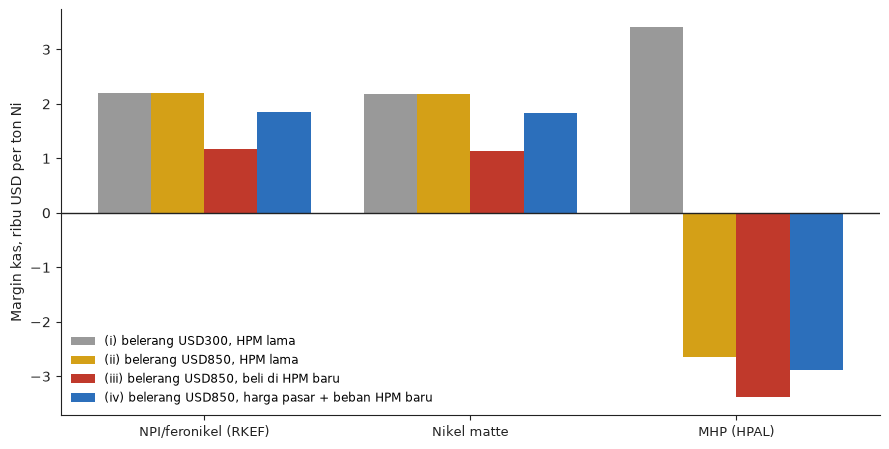

,"(i) belerang USD300, HPM lama","(ii) belerang USD850, HPM lama","(iii) belerang USD850, beli di HPM baru","(iv) belerang USD850, harga pasar + beban HPM baru"
NPI/feronikel (RKEF),2.2,2.2,1.2,1.9
Nikel matte,2.2,2.2,1.1,1.8
MHP (HPAL),3.4,-2.6,-3.4,-2.9


In [12]:
# --- asumsi 2026: tebakan berpendidikan dari pemberitaan, bukan data resmi ---
lme26, pb26 = 15_500, h.loc[2025, "bb_fob"]
roy_ore26, pph = 0.15, 0.22                      # royalti bijih (rezim PP 19/2025) dan PPh badan
sap = {"hpm_lama": hpm_lama(0.017, lme26)}
sap["pasar"] = sap["hpm_lama"] + 24              # premi 2025 bertahan
sap["hpm_baru"] = 0.017 * 0.31 * lme26 * (1 - air) + 12   # CF Ni ~31% + kredit Fe/Co ~USD12
lim = {"hpm_lama": hpm_lama(0.012, lme26), "hpm_baru": 26.0}
lim["pasar"] = lim["hpm_lama"] + 5

# harga produk per ton Ni: rasio harga ekspor 2025 terhadap LME 2025
e25 = eks.query("tahun == 2025 & hs in @KADAR").assign(ni=lambda d: d.netWgt / 1000 * d.hs.map(KADAR))
rasio = lambda kode: e25.query("hs in @kode").primaryValue.sum() / e25.query("hs in @kode").ni.sum() / h.loc[2025, "nikel"]
r_npi, r_matte, r_mhp = rasio(["720260"]), rasio(["750110"]), rasio(["750120"])
k_roy = df.attrs["k"]

def margin_2026(sulfur, kasus):
    # kasus: 'lama' (harga pasar, royalti atas HPM lama), 'baru' (beli di HPM baru),
    # 'renego' (harga pasar + royalti dan PPh atas selisih HPM baru - pasar dibebankan ke smelter)
    ps, pl = sap["pasar"], lim["pasar"]
    if kasus == "baru":
        ps, pl = sap["hpm_baru"], lim["hpm_baru"]
    if kasus == "renego":
        beban = roy_ore26 + pph * (1 - roy_ore26)
        ps += max(sap["hpm_baru"] - sap["pasar"], 0) * beban
        pl += max(lim["hpm_baru"] - lim["pasar"], 0) * beban
    upah = upah_dom + upah_tka
    kas_npi = bijih_rkef * ps + bb_rkef * pb26 + lain_rkef + upah
    rows = {}
    for nama, harga, kas, roy in [
        ("NPI/feronikel (RKEF)", r_npi * lme26, kas_npi, roy_rkef[2025]),
        ("Nikel matte", r_matte * lme26, kas_npi + konverter + bb_matte * pb26, roy_rkef[2025]),
        ("MHP (HPAL)", r_mhp * lme26,
         bijih_hpal * pl + s_hpal * sulfur + bb_hpal * pb26 + lain_hpal + kapur_hpal + upah, roy_hpal[2025]),
    ]:
        rows[nama] = harga - kas - k_roy * roy * harga
    return pd.Series(rows)

KASUS = {"(i) belerang USD300, HPM lama": (300, "lama"),
         "(ii) belerang USD850, HPM lama": (850, "lama"),
         "(iii) belerang USD850, beli di HPM baru": (850, "baru"),
         "(iv) belerang USD850, harga pasar + beban HPM baru": (850, "renego")}
m26 = pd.DataFrame({k: margin_2026(*v) for k, v in KASUS.items()})
print(f"Harga bijih 2026 (USD/ton basah): saprolit 1,7% HPM lama {sap['hpm_lama']:.0f}, pasar {sap['pasar']:.0f}, "
      f"HPM baru {sap['hpm_baru']:.0f}; limonit 1,2% HPM lama {lim['hpm_lama']:.0f}, pasar {lim['pasar']:.0f}, "
      f"HPM baru {lim['hpm_baru']:.0f}")

fig, ax = plt.subplots(figsize=(9, 4.6))
w = 0.2
warna26 = [abu, emas, merah, biru]
for i, (kol, c) in enumerate(zip(m26.columns, warna26)):
    ax.bar(np.arange(len(m26)) + (i - 1.5) * w, m26[kol] / 1e3, width=w, color=c, label=kol)
ax.axhline(0, color=ink, lw=1)
ax.set_xticks(np.arange(len(m26)))
ax.set_xticklabels(m26.index, fontsize=9)
ax.set_ylabel("Margin kas, ribu USD per ton Ni")
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.tight_layout()
plt.show()
(m26 / 1e3).round(1)

RKEF masih bertahan. Marginnya turun dari sekitar USD2.200 ke USD1.200–1.900 per ton Ni, tergantung seberapa jauh HPM baru benar-benar dibayar. HPAL, jalur "baterai" yang menjadi alasan utama larangan ekspor, langsung **negatif**: dari sekitar +USD3.400 menjadi −USD2.600 sampai −USD3.400 per ton Ni. Sebagian besar kerusakan ini datang dari belerang, bukan dari HPM. HPM baru tinggal menambah beban di atasnya.

Lalu apa dampaknya ke hitungan $D$ dan $C$? Tabel 5 menghitung ulang untuk 2026 (miliar USD) dengan volume sekitar 97% volume 2025, dan memakai margin kas sebagai proksi $\Pi$.

In [13]:
# dampak ke perhitungan D dan C, volume 2026 ~97% volume 2025 (RKAB lebih ketat), bijih impor seperti 2025
d25 = dekomposisi().loc[2025]
sap_dom25 = d25.ni_rkef * bijih_rkef - imp_bijih.loc[2025, "berat"] / 1000 * 0.014 / 0.017
lim25 = d25.ni_hpal * bijih_hpal
f = 0.97
hasil26 = {}
for nama, (sulfur, kasus) in KASUS.items():
    ps, pl = sap["pasar"], lim["pasar"]
    if kasus == "baru":
        ps, pl = sap["hpm_baru"], lim["hpm_baru"]
    if kasus == "renego":
        beban = roy_ore26 + pph * (1 - roy_ore26)
        ps += (sap["hpm_baru"] - sap["pasar"]) * beban
        pl += (lim["hpm_baru"] - lim["pasar"]) * beban
    B = f * (sap_dom25 * ps + lim25 * pl)
    ni = f * pd.Series({"NPI/feronikel (RKEF)": d25.ni_rkef, "MHP (HPAL)": d25.ni_hpal})
    # margin kas sebelum penyusutan; semua Ni jalur RKEF (termasuk matte dan baja) memakai margin NPI
    Pi = m26.loc["NPI/feronikel (RKEF)", nama] * ni.iloc[0] + m26.loc["MHP (HPAL)", nama] * ni.iloc[1]
    Wd = f * d25.Wd
    R = f * d25.R
    L = f * d25.L
    D = B + L + Wd + R + 0.25 * Pi
    C = f * (sap_dom25 * hb.loc[2025, "dunia"] + lim25 * lim["pasar"])
    hasil26[nama] = {"Bijih domestik, B": B, "Margin kas smelter": Pi, "Tertahan, D": D,
                     "Kontrafaktual ekspor bijih, C (batas A)": C, "G = D - C": D - C}
tabel26 = pd.DataFrame(hasil26) / 1e9
tambah_negara = (roy_ore26 + pph * (1 - roy_ore26)) * (
    (sap["hpm_baru"] - sap["hpm_lama"]) * f * sap_dom25 + (lim["hpm_baru"] - lim["hpm_lama"]) * f * lim25)
print(f"Tambahan royalti + PPh dari HPM baru vs HPM lama: ~USD{tambah_negara / 1e9:.1f} miliar per tahun")
tabel26.round(1)

Tambahan royalti + PPh dari HPM baru vs HPM lama: ~USD2.2 miliar per tahun


,"(i) belerang USD300, HPM lama","(ii) belerang USD850, HPM lama","(iii) belerang USD850, beli di HPM baru","(iv) belerang USD850, harga pasar + beban HPM baru"
"Bijih domestik, B",10.7,10.7,12.9,11.5
Margin kas smelter,5.9,2.4,0.1,1.6
"Tertahan, D",18.9,18.1,19.6,18.6
"Kontrafaktual ekspor bijih, C (batas A)",9.7,9.7,9.7,9.7
G = D - C,9.3,8.4,10.0,8.9


Ada beberapa hal yang menarik dari Tabel 5:
- **Margin kas smelter anjlok**, dari sekitar USD6 miliar menjadi USD0,1–2,4 miliar.
- **Yang tertahan di Indonesia ($D$) hampir tidak berubah**, sekitar USD18–20 miliar.
- Tambahan royalti dan PPh dari HPM baru dibanding HPM lama kira-kira **USD2,2 miliar per tahun**. Ini cuma tebakan, karena sangat bergantung pada volume RKAB dan harga pasar yang mana saya ga punya infonya.
- Dalam skenario HPM baru, sekitar **62–66%** dari $D$ adalah pembayaran bijih ke penambang dan negara. Pengolahannya sendiri hanya menyumbang sisanya.

HPM baru dan RKAB yang ketat memindahkan nilai dari $\Pi_t$, yang 75%-nya milik asing, ke $B_t$ dan royalti, yang tertahan di dalam negeri. Negara pada dasarnya sedang menagih kembali sewa bijih yang dulu "dihadiahkan" ke smelter lewat larangan ekspor. Ini sekaligus pengakuan implisit bahwa nilai tambah domestik terbesar memang ada di **bijihnya**, bukan di pengolahannya, persis argumen bahwa bijihnya aja sebenarnya sudah memberi nilai tambah domestik yang besar.

Hitungan ini juga belum memasukkan volume yang hilang. Kalau HPAL rugi, sebagian akan berhenti beroperasi, dan $D$ ikut turun lewat upah dan royalti produk yang hilang. Jadi Tabel 5 kemungkinan terlalu optimis untuk HPAL.

## Kalau tujuannya "sewa" bijih, kenapa tidak pajak ekspor saja?

Kalau ujung-ujungnya negara harus memangkas kuota dan menaikkan HPM untuk menagih sewa bijih, ada cara yang jauh lebih sederhana: **buka ekspor bijih, tapi kenakan pajak ekspor**. Indonesia memegang sekitar 60% pasokan nikel dunia, jadi Indonesia punya kekuatan pasar. Dalam kondisi seperti ini, teori perdagangan bilang pajak ekspor yang optimal bisa memindahkan sebagian beban ke pembeli asing lewat harga dunia yang lebih tinggi. Ini mirip logika OPEC, dan persis yang sekarang dicoba lewat RKAB, cuma lewat jalan memutar.

Pajak ekspor bijih punya beberapa kelebihan dibanding larangan ekspor + RKAB + HPM:
- **Sewanya langsung masuk APBN**, transparan, dan tercatat. Tidak perlu menebak-nebak berapa royalti yang hilang karena basis HPM di bawah harga pasar.
- **Smelter tetap bisa beroperasi, tapi harus bersaing** dengan pembeli bijih di luar negeri. Smelter yang memang efisien tetap untung karena hemat ongkos kapal. Smelter yang cuma hidup dari bijih murah akan tersaring.
- **Penambang dapat harga dunia dikurangi pajak**, bukan harga yang ditentukan segelintir pembeli. Insentif untuk menyelundup ke Tiongkok juga berkurang.

Tentu ada kelemahannya: pajak ekspor yang terlalu tinggi bisa menurunkan volume, dan harus dirancang supaya tidak gampang diakali dengan _under-invoicing_ (yang, seperti terlihat di data ekspor bijih sebelum 2014, sangat mungkin terjadi). Pemerintah sendiri sempat berencana mengenakan bea keluar untuk produk nikel olahan mulai April 2026, lalu menundanya ([Mysteel](https://www.mysteel.net/news/5117812-flash-indonesia-postpones-implementation-of-coal-and-nickel-export-duties)). Ironisnya, yang mau dipajaki justru produk olahannya, bukan bijihnya.

Jangan lupa juga bahwa sekarang sudah terlambat untuk pajak ekspor nikel karena kapasitas smelter domestik sudah sangat besar. Pembelian domestik saat inipun sudah kompetitif bahkan sampai smelter-smelter ini bisa bersaing dengan pasar global dalam membeli ores dari Filipina.

Jadi, teori saya **salah** di pertanyaan utamanya, tapi benar di beberapa hal penting:

1. **Hilirisasi tetap lebih baik dari ekspor bijih, tapi angka "1,7 jadi 34 miliar dolar" menyesatkan.** Nilai tambah dari pengolahan yang tertahan di Indonesia sekitar 24–33% dari ekspor. Tambahan bersihnya dibanding skenario ekspor bijih sekitar 19–26% dari ekspor kotor kumulatif, dan bisa jauh lebih kecil kalau biaya kas lain ternyata banyak yang impor.
2. **Di awal larangan (2020–2021), manfaat bersihnya tipis**, sekitar USD1 miliar per tahun, jauh lebih kecil dari transfer penambang ke smelter (sekitar USD5–10 miliar selama 2020–2022). Kalau biaya kas lain kebanyakan impor, manfaatnya malah negatif.
3. **Manfaat bersih membesar ketika harga bijih domestik mengejar harga dunia**, dan di 2026 negara secara eksplisit menagih sewa bijih lewat RKAB dan HPM baru. Sekitar separuh dari yang tertahan di Indonesia di 2025 adalah pembayaran bijih. Nilai tambah domestik terbesar memang ada di bijihnya.

Ada banyak hal yang **belum** masuk hitungan, dan sebagian besar bisa menggeser hasilnya ke arah mana pun:

1. **Eksternalitas lingkungan dan kesehatan.** Ada 15,4 GW PLTU _captive_ yang melayani smelter nikel ([CREA–GEM, 2026](https://energyandcleanair.org/wp/wp-content/uploads/2026/02/EN-CREA_GEM_Indonesia-captive-coal-in-2025_REV.pdf)). Dengan koefisien di Tabel 1, batubara yang dibakar untuk produk nikel yang diekspor naik dari sekitar 12,6 juta ton di 2019 menjadi 62 juta ton di 2025. Laporan CREA–GEM yang sama mencatat 99 juta ton untuk seluruh sektor logam dan metalurgi. Selain itu ada deforestasi dan pencemaran laut. [CREA–CELIOS (2024)](https://energyandcleanair.org/wp/wp-content/uploads/2024/02/CREA_CELIOS-Indonesia-Nickel-Development_EN.pdf) memperkirakan biaya kesehatan dan kerugian petani serta nelayan bisa membuat manfaat ekonomi hilirisasi negatif mulai tahun ke-9. Kalau ini dihitung, $G_t$ jelas lebih kecil.
2. **Volume kontrafaktual.** Saya mengasumsikan tanpa larangan pun Indonesia akan mengekspor bijih dengan kandungan nikel yang sama (2,4 juta ton Ni di 2025). Ini berlebihan, karena pasar bijih dunia (sekitar 40 juta ton per tahun) tidak sebesar itu. Saya kasih diskon 25% di batas B sebagai ancer-ancer, tapi itupun cuma tebakan yang agak _arbitrary_.
3. **Kepemilikan tambang.** Saya anggap seluruh pembayaran bijih domestik dinikmati domestik. Kenyataannya banyak tambang dimiliki atau dikendalikan grup smelter juga, jadi $D_t$ kemungkinan lebih kecil.
4. **_Tax holiday_.** $\Pi_t$ di atas sudah termasuk PPh badan, yang saya anggap nol. Smelter yang masuk kategori industri pionir kemungkinan bisa mendapat pengurangan PPh badan 100% selama 5–20 tahun, tergantung nilai investasinya, ditambah pengurangan 50% selama dua tahun sesudahnya (PMK 130/2020). Saya tidak menemukan angka berapa yang benar-benar dinikmati smelter nikel. Sebagai gambaran kasar: kalau laba kena pajak sekitar 40–60% dari $\Pi_t$ (sisanya penyusutan dan bunga), PPh yang tidak dipungut sekitar USD0,5–1,6 miliar per tahun di 2020–2025. Karena 75% laba itu milik asing, tanpa _tax holiday_ $D_t$ akan lebih besar sekitar USD3,5–5 miliar secara kumulatif. Tidak semua smelter mendapat fasilitas ini, jadi anggap ini batas atas.
5. **Transfer pricing.** Eventually barang setengah jadinya kan diekspor ke utamanya Tiongkok. Kalau ekspor ini ternyata adalah bagian dari _vertical integration_ dengan induk perusahaan dan Kalau harga ekspor ke induk di Tiongkok tersebut ada di bawah harga pasar, maka $X_t$ dan $\Pi_t$ di Indonesia sama-sama lebih kecil dari yang seharusnya. Nilai tambah yang benar-benar diciptakan lebih besar, tapi yang lari juga lebih besar.
6. **Manfaat dinamis.** _Learning-by-doing_, teknologi, dan ekosistem baterai sama sekali tidak terhitung. Ini argumen terkuat pendukung hilirisasi. Literatur _infant industry_ bilang proteksi **bisa** menguntungkan kalau pembelajarannya nyata dan industrinya akhirnya mandiri[^1]. Tapi dengan 83% nikel masih masuk ke baja nirkarat, LG yang mundur, dan HPAL yang kini rugi begitu harga belerang naik, buktinya sejauh ini masih tipis.
7. Ini **hitungan akuntansi statis**, bukan model keseimbangan umum. Efeknya ke harga nikel dunia, nilai tukar, dan sektor lain tidak dimodelkan. Semua dianggap _ceteris paribus_, wicis ga bener.

Tapi poin utamanya tetap. Pertanyaan yang benar bukan "berapa ekspornya", tapi "berapa yang **nilai tambah yang tertangkap** di sini, dibanding kalau kita tidak melakukan apa-apa". Selama yang dilaporkan cuma nilai ekspor kotor, kita tidak akan pernah tahu apakah sebuah kebijakan industri berhasil. Sama seperti [TKDN kereta]({{< relref "/post/kereta" >}}), kebijakan ini juga tidak gratis: di 2020–2022 ongkosnya dibayar penambang lewat harga bijih yang ditekan, dan sepanjang waktu dibayar warga sekitar smelter lewat udara dan laut yang tercemar. Ongkos ini tidak muncul di angka ekspor.

## Bagaimana memperbaiki hitungan ini?

Hampir semua tebakan di atas sebenarnya ada datanya, hanya saja tidak publik. Sebagian besar justru dipegang pemerintah:

1. **Harga dan volume bijih yang sebenarnya.** Kementerian ESDM mencatat penjualan bijih per pemegang izin, termasuk kadar, volume, harga transaksi, dan pembelinya, lewat sistem pelaporan minerba dan SIMBARA, sistem pelacakan komoditas minerba antar-kementerian yang sekarang juga mencakup nikel. Data ini bisa menggantikan tebakan premi dan diskon HPM saya, dan menjawab langsung berapa transfer dari penambang ke smelter.
2. **Royalti yang benar-benar dibayar**, dipisah antara bijih dan produk olahan, per perusahaan. Ini cek silang yang paling langsung:
   - royalti bijih dibagi tarifnya memberi nilai bijih menurut basis HPM, yang bisa dibandingkan dengan $B_t$;
   - royalti produk dibagi tarifnya memberi nilai produk olahan menurut harga acuan, yang bisa dibandingkan dengan nilai ekspor $X_t$. Selisih yang besar bisa menandakan basis harga acuan yang terlalu rendah, atau _transfer pricing_.

   Saya terpaksa memakai satu faktor kalibrasi (0,40) untuk semua royalti, padahal pemisahan ini mungkin yang paling informatif soal nilai tambah domestik yang benar-benar masuk ke negara.
3. **Struktur biaya smelter.** Survei Industri Besar dan Sedang BPS mencatat output, upah, listrik, bahan bakar, dan bahan baku per pabrik, dengan bahan baku dipisah antara domestik dan impor. Ini persis yang dibutuhkan untuk memecah $L_t$ dan memperbaiki Tabel 1. Tabel input-output BPS yang lebih baru juga membantu.
4. **Laba, pajak, dan _tax holiday_.** DJP punya SPT badan, dokumentasi _transfer pricing_ perusahaan smelter, dan data fasilitas _tax holiday_ yang benar-benar dipakai. Ini bisa menggantikan tebakan 40–60% laba kena pajak saya. Laporan belanja perpajakan Kemenkeu sudah memuat angka _tax holiday_ secara agregat, dan pemisahan per sektor saja sudah sangat membantu.
5. **Aliran laba ke luar negeri.** Bank Indonesia mengumpulkan data dividen, laba ditahan, dan bunga pinjaman per perusahaan PMA untuk statistik neraca pembayaran, juga data devisa hasil ekspor yang wajib ditahan di dalam negeri. Ini bisa menguji $\theta$ dan $\Pi_t$ secara langsung, bukan lewat proksi kepemilikan.
6. **Investasi dan tenaga kerja.** Laporan kegiatan penanaman modal (LKPM) berisi realisasi investasi serta jumlah pekerja Indonesia dan TKA per perusahaan, dan data BPJS Ketenagakerjaan berisi upah yang sebenarnya. Ini bisa memperbaiki $W^d_t$ dan $W^f_t$.
7. **Harga dan isi ekspor per transaksi.** Dokumen ekspor di Bea Cukai mencatat harga, berat, pembeli, dan apakah pembelinya pihak berelasi. Ini bisa memisahkan NPI dari feronikel, mengecek kadar, dan mendeteksi _transfer pricing_.

Kalau data ini dibuka, setidaknya secara agregat per jalur produksi, perdebatan soal hilirisasi bisa pindah dari "ekspornya naik 20 kali lipat" ke pertanyaan yang lebih jujur: berapa yang benar-benar tertahan di Indonesia.

Disclaimer dulu: saya bukan ahli metalurgi. Semua koefisien teknis di atas adalah perkiraan kasar dari literatur dan laporan perusahaan, dan sebagian (terutama reduktan, biaya lain, upah, premi harga bijih, dan semua angka 2026) cukup spekulatif. Kode dan datanya ada di folder post ini, silakan diganti asumsinya kalau punya angka yang lebih baik. Saya akan senang sekali dikoreksi.

Gitu dulu kali ya. Mention saya di [twitter](https://www.twitter.com/imedkrisna) yah jika ada komen, kritik, atau saran. Tengkyuu.

[^1]: Melitz, M. J. (2005). When and How Should Infant Industries Be Protected? *Journal of International Economics*, 66(1), 177–196. https://doi.org/10.1016/j.jinteco.2004.07.001